# Phys and Bio variables visualization

## Map

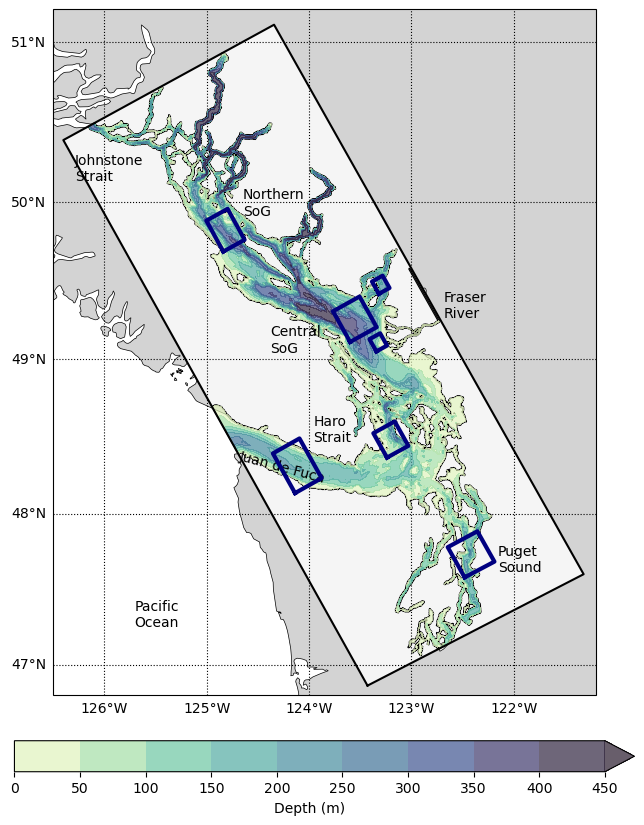

In [15]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cmocean
import cartopy.feature as cfeature
from cartopy import crs, feature
from cartopy.mpl.gridliner import (
    LONGITUDE_FORMATTER,
    LATITUDE_FORMATTER,
)

# ============================================================
# 1. Load model grid / mask
# ============================================================

grid = xr.open_dataset(
    "/ocean/ksuchy/MOAD/NEMO-forcing/grid/bathymetry_202108.nc",
    mask_and_scale=False,
)

mask = xr.open_dataset(
    "/ocean/ksuchy/MOAD/NEMO-forcing/grid/mesh_mask202108.nc"
)

lon = grid.nav_lon.values
lat = grid.nav_lat.values
bathy = grid.Bathymetry.values

# Surface ocean mask:
# 1 = water, 0 = land
tmask = mask.tmask[0, 0, :, :].values


# ============================================================
# 2. Helper: draw a box defined in NEMO grid-index space
# ============================================================

def plot_grid_box(ax, j0, j1, i0, i1,
                  color="navy", linewidth=3):
    """
    Draw a rectangular region whose bounds are given by
    NEMO grid indices.

    j0, j1 : y-index limits
    i0, i1 : x-index limits
    """

    corners = [
        (j0, i0),
        (j0, i1),
        (j1, i1),
        (j1, i0),
        (j0, i0),
    ]

    box_lon = [lon[j, i] for j, i in corners]
    box_lat = [lat[j, i] for j, i in corners]

    ax.plot(
        box_lon,
        box_lat,
        color=color,
        linewidth=linewidth,
        transform=crs.PlateCarree(),
        zorder=5,
    )


# ============================================================
# 3. Make map
# ============================================================

xlim = [-126.5, -121.2]
ylim = [46.8, 51.2]

fig, ax = plt.subplots(
    figsize=(8, 10),
    subplot_kw={
        "projection": crs.Mercator(
            central_longitude=np.mean(xlim)
        )
    },
)

ax.set_extent(
    [xlim[0], xlim[1], ylim[0], ylim[1]],
    crs=crs.PlateCarree(),
)


# ============================================================
# 4. Geographic coastline / land
# ============================================================

# ax.add_feature(
#     feature.GSHHSFeature(
#         scale="full",
#         edgecolor="black",
#         facecolor="lightgrey",
#     ),
#     zorder=0,
# )

ax.add_feature(
    cfeature.LAND.with_scale("10m"),
    facecolor="lightgrey",
    edgecolor="black",
    linewidth=0.5,
    zorder=0,
)


# ============================================================
# 5. Model domain land/water boundary
# ============================================================

# Similar to the original notebook:
# overlay the model mask to show the actual NEMO model domain.

ax.contourf(
    lon,
    lat,
    tmask,
    levels=[-0.01, 0.01],
    colors=["whitesmoke"],
    transform=crs.PlateCarree(),
    zorder=1,
)

ax.contour(
    lon,
    lat,
    tmask,
    levels=[0.01],
    colors="black",
    linewidths=0.8,
    transform=crs.PlateCarree(),
    zorder=2,
)


# ============================================================
# 6. Draw outer model-domain boundary
# ============================================================

domain_corners = [
    (0, 0),
    (0, -1),
    (-1, -1),
    (-1, 0),
    (0, 0),
]

domain_lon = [lon[j, i] for j, i in domain_corners]
domain_lat = [lat[j, i] for j, i in domain_corners]

ax.plot(
    domain_lon,
    domain_lat,
    "k-",
    linewidth=1.5,
    transform=crs.PlateCarree(),
    zorder=4,
)


# ============================================================
# 7. Bathymetry
# ============================================================

# Mask land cells
bathy_masked = np.ma.masked_where(
    tmask == 0,
    bathy,
)

depth_levels = np.arange(0, 451, 50)

c = ax.contourf(
    lon,
    lat,
    bathy_masked,
    levels=depth_levels,
    cmap=cmocean.cm.deep,
    extend="max",
    alpha=0.7,
    transform=crs.PlateCarree(),
    zorder=3,
)


# ============================================================
# 8. Draw study-region boxes
# ============================================================

# These are copied from the original notebook.
# Format:
# name: (j0, j1, i0, i1)

regions = {
    "Central SoG":  (450, 500, 250, 300),
    "Juan de Fuca": (300, 365,  50, 100),
    "Haro Strait":  (280, 320, 210, 250),
    "Northern SoG": (650, 700, 140, 180),
    "Puget Sound":  (75,  125, 225, 280),
    "Pam Rocks": (490, 510, 330, 350),
    "SandHeads": (420, 440, 280, 300),
}

for name, (j0, j1, i0, i1) in regions.items():
    plot_grid_box(
        ax,
        j0, j1,
        i0, i1,
        color="navy",
        linewidth=3,
    )


# ============================================================
# 9. Gridlines
# ============================================================

xlocs = np.arange(
    np.floor(xlim[0]),
    np.ceil(xlim[1]) + 1,
    1,
)

ylocs = np.arange(
    np.floor(ylim[0]),
    np.ceil(ylim[1]) + 1,
    1,
)

gl = ax.gridlines(
    draw_labels=True,
    xlocs=xlocs,
    ylocs=ylocs,
    linestyle=":",
    color="black",
)

gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER
gl.top_labels = False
gl.right_labels = False


# ============================================================
# 10. Labels
# ============================================================

# These positions are axis-relative.
ax.text(
    0.15, 0.10,
    "Pacific\nOcean",
    transform=ax.transAxes,
)

ax.text(
    0.82, 0.18,
    "Puget\nSound",
    transform=ax.transAxes,
)

ax.text(
    0.34, 0.31,
    "Juan de Fuca",
    rotation=-15,
    transform=ax.transAxes,
)

ax.text(
    0.40, 0.50,
    "Central\nSoG",
    transform=ax.transAxes,
)

ax.text(
    0.35, 0.70,
    "Northern\nSoG",
    transform=ax.transAxes,
)

ax.text(
    0.04, 0.75,
    "Johnstone\nStrait",
    transform=ax.transAxes,
)

ax.text(
    0.48, 0.37,
    "Haro\nStrait",
    transform=ax.transAxes,
)

ax.text(
    0.72, 0.55,
    "Fraser\nRiver",
    transform=ax.transAxes,
)


# ============================================================
# 11. Colorbar
# ============================================================

cbar = fig.colorbar(
    c,
    ax=ax,
    orientation="horizontal",
    pad=0.06,
    fraction=0.05,
)

cbar.set_label("Depth (m)")


# ============================================================
# 12. Show
# ============================================================

# plt.savefig(
#     "Figure1_StudyAreaMap_clean.png",
#     dpi=300,
#     bbox_inches="tight",
# )

plt.show()

## Results Visualization

In [ ]:
# paths

path_bio='/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/biological/'
path_phy='/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/physical/'

locations=["Central SoG",
    "Juan_de_Fuca",
    "Haro_Strait",
    "Northern_SoG",
    "Puget_Sound",
    "Pam_Rocks",
    "SandHeads"]

tail_bio='_biological.csv'
tail_phy='_physical.csv'

# Example path:
# /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/physical/Central_SoG_physical.csv
# /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/biological/Central_SoG_biological.csv

### Phy

Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/physical/Central_SoG_physical.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/physical/Juan_de_Fuca_physical.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/physical/Haro_Strait_physical.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/physical/Northern_SoG_physical.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/physical/Puget_Sound_physical.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/physical/Pam_Rocks_physical.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmosphe

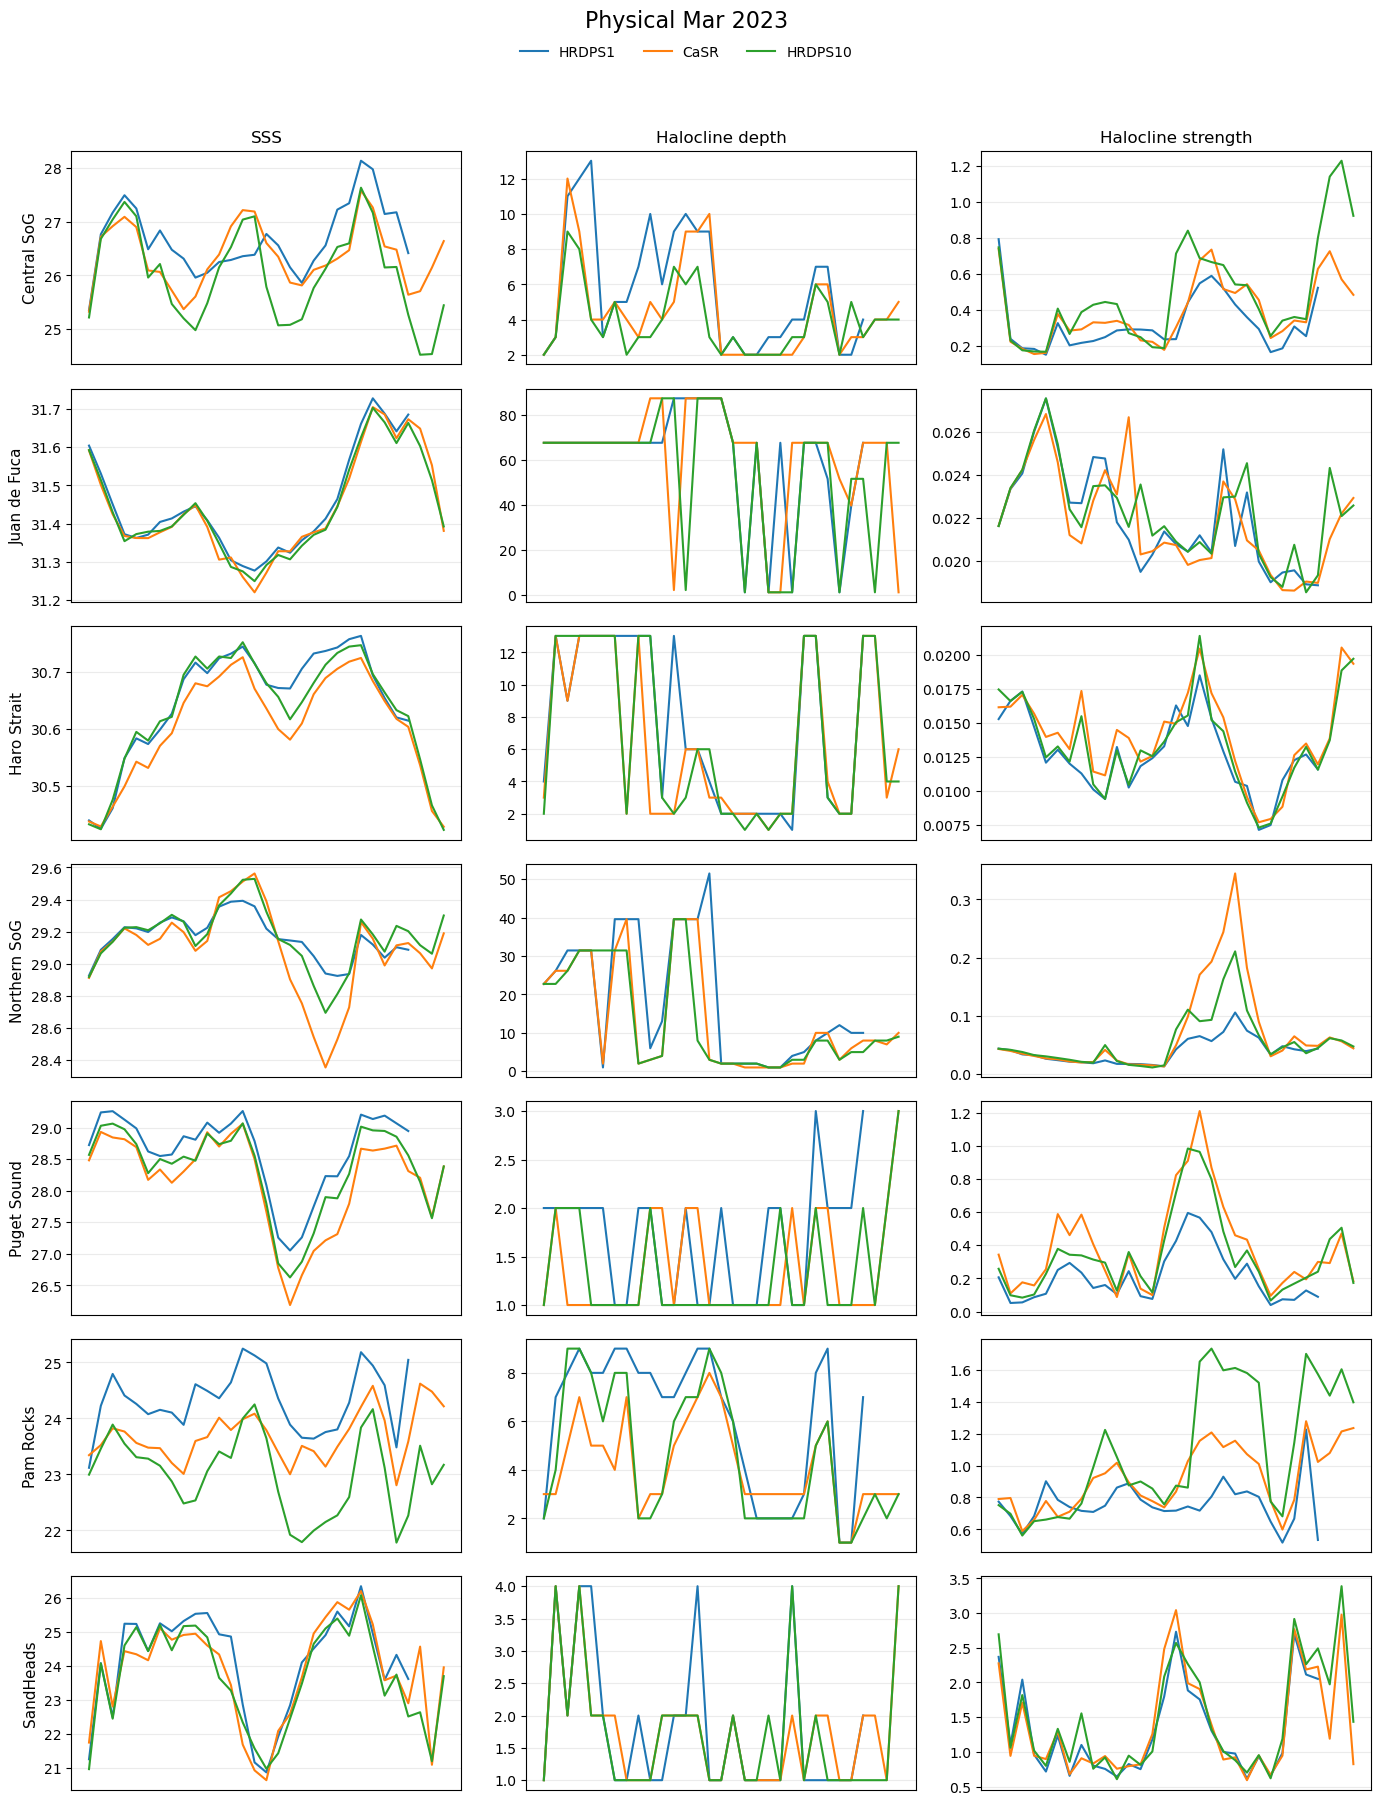

In [6]:

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. PATH
# ============================================================

DATA_DIR = Path(
    "/home/jqiu/analysis-junqi/"
    "Analysis_Atmospheric_Forcing/"
    "Analysis_results_comparison/"
    "Analysis_4_months/Data_4_months/physical/"
)


# ============================================================
# 2. SETTINGS
# ============================================================

# month to plot
MONTH = "Mar"  # "Mar", "Jun", "Sep", "Dec"

REGIONS = [
    "Central SoG",
    "Juan_de_Fuca",
    "Haro_Strait",
    "Northern_SoG",
    "Puget_Sound",
    "Pam_Rocks",
    "SandHeads",
]

MODELS = [
    "HRDPS1",
    "CaSR",
    "HRDPS10",
]

VARIABLES = [
    ("SSS", "SSS"),
    ("halocline_depth_m", "Halocline depth"),
    (
        "halocline_strength_psu_per_m",
        "Halocline strength",
    ),
]


# ============================================================
# 3. HELPERS
# ============================================================

def safe_filename(name):
    return name.replace(" ", "_")


# ============================================================
# 4. PLOT
# ============================================================

fig, axes = plt.subplots(
    nrows=len(REGIONS),
    ncols=len(VARIABLES),
    figsize=(14, 18),
)

for row, region in enumerate(REGIONS):

    filename = (
        DATA_DIR /
        f"{safe_filename(region)}_physical.csv"
    )

    print(f"Reading: {filename}")

    if not filename.exists():
        print(f"WARNING: file not found: {filename}")
        continue

    df = pd.read_csv(filename)

    # Select the specified month
    df = df[df["month"] == MONTH].copy()

    if df.empty:
        print(f"WARNING: no data for {MONTH} in {region}")
        continue

    # Sort by date
    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values("date")

    x = df["date"]

    for col, (var_name, var_title) in enumerate(VARIABLES):

        ax = axes[row, col]

        for model in MODELS:

            column_name = f"{model}__{var_name}"

            if column_name not in df.columns:
                print(
                    f"WARNING: missing column: {column_name}"
                )
                continue

            ax.plot(
                x,
                df[column_name],
                label=model,
                linewidth=1.5,
            )

        # Column title only on top row
        if row == 0:
            ax.set_title(var_title, fontsize=12)

        # Region name only on left column
        if col == 0:
            ax.set_ylabel(
                region.replace("_", " "),
                fontsize=11,
            )

        # Hide date labels
        ax.set_xticks([])

        ax.grid(alpha=0.25)


# ============================================================
# 5. ONE SHARED LEGEND
# ============================================================

# Collect legend handles from all axes
legend_dict = {}

for ax in axes.flat:
    handles, labels = ax.get_legend_handles_labels()

    for handle, label in zip(handles, labels):
        legend_dict[label] = handle

fig.legend(
    legend_dict.values(),
    legend_dict.keys(),
    loc="upper center",
    ncol=len(MODELS),
    bbox_to_anchor=(0.5, 0.985),
    frameon=False,
)

fig.suptitle(
    f"Physical {MONTH} 2023",
    fontsize=16,
    y=0.998,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)





plt.show()


Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/physical/Central_SoG_physical.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/physical/Juan_de_Fuca_physical.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/physical/Haro_Strait_physical.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/physical/Northern_SoG_physical.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/physical/Puget_Sound_physical.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/physical/Pam_Rocks_physical.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmosphe

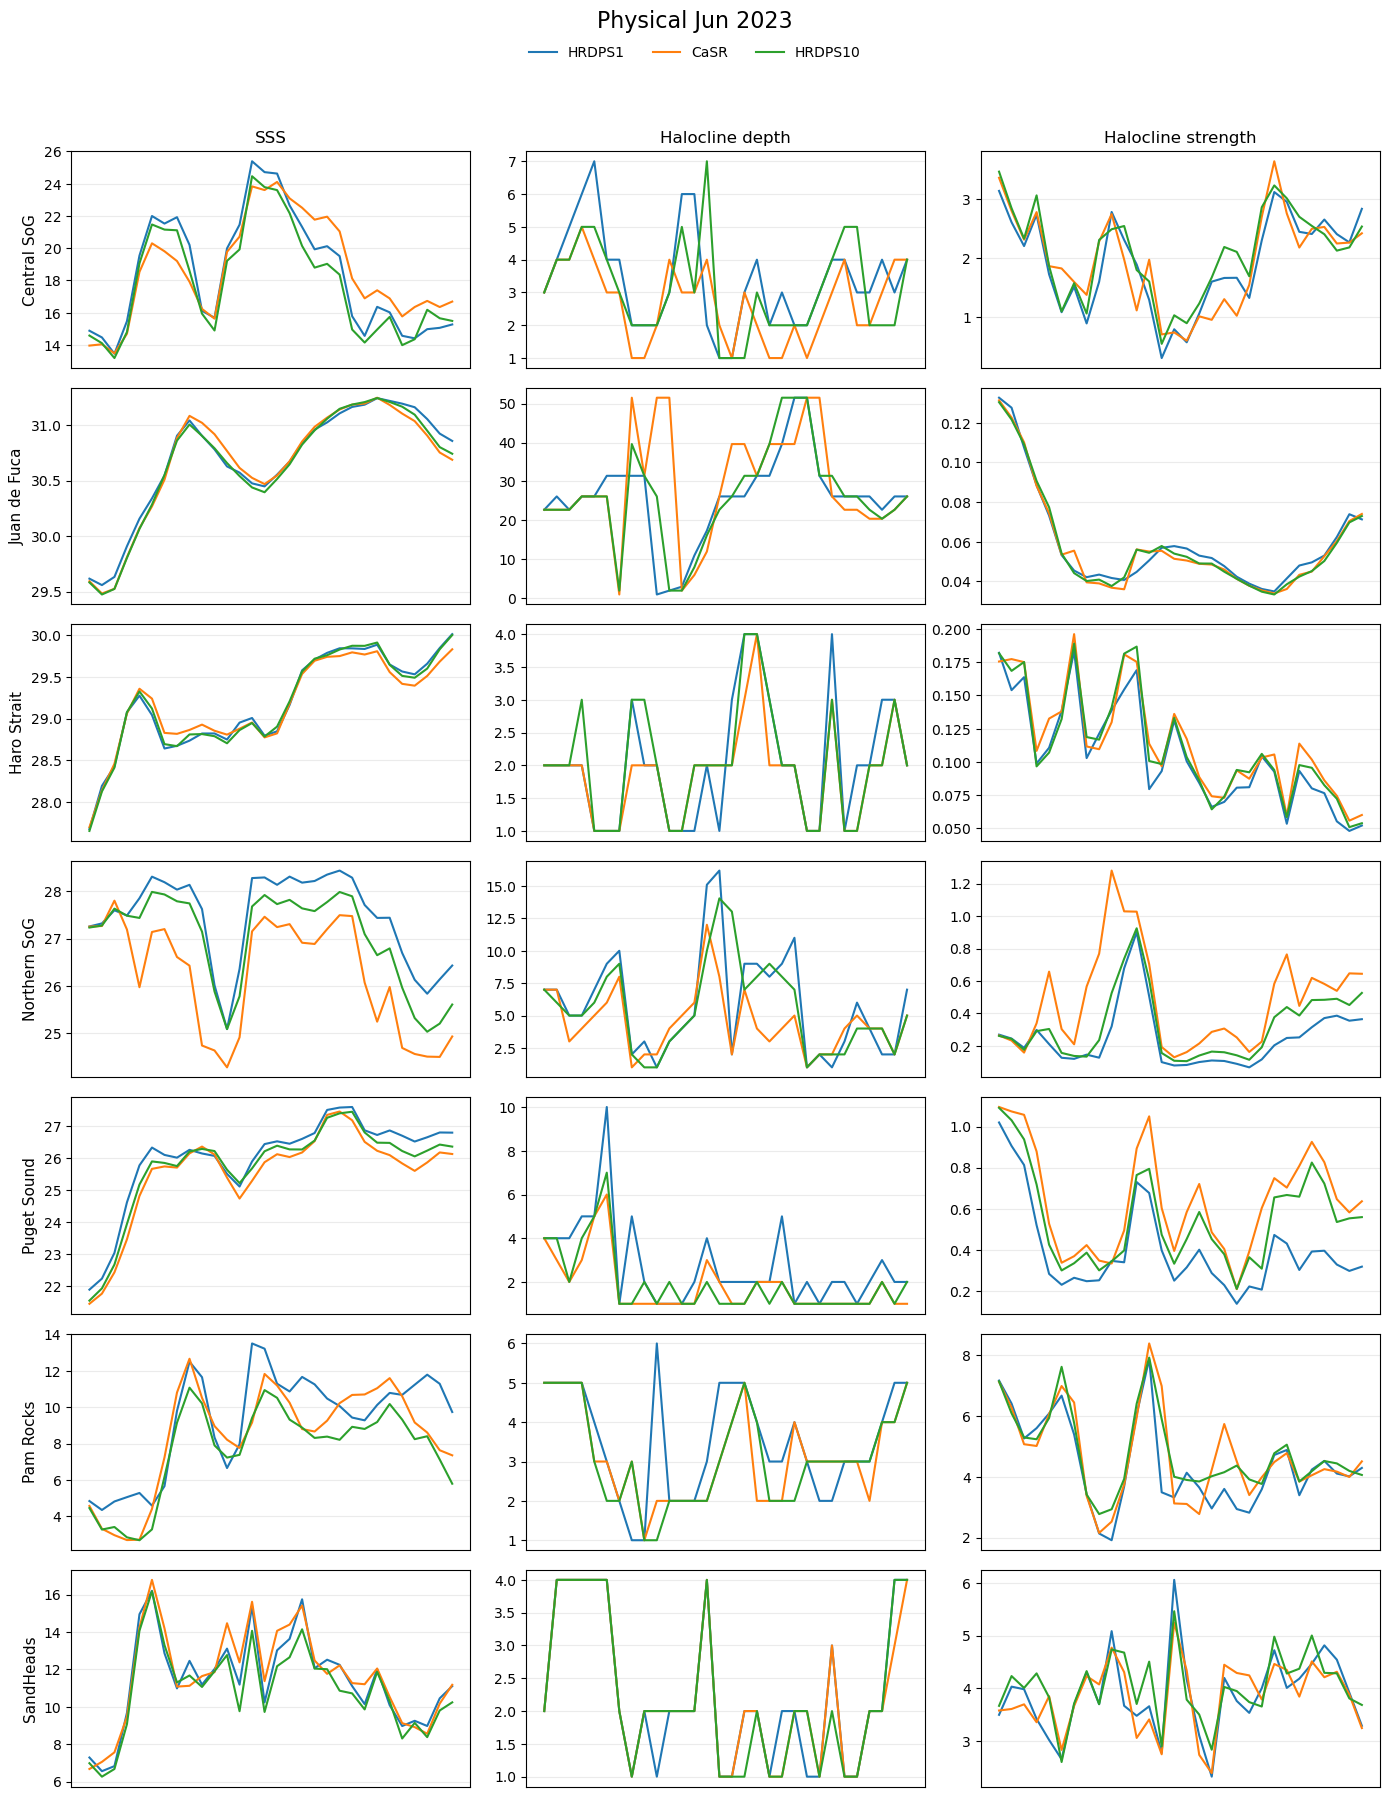

In [7]:

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. PATH
# ============================================================

DATA_DIR = Path(
    "/home/jqiu/analysis-junqi/"
    "Analysis_Atmospheric_Forcing/"
    "Analysis_results_comparison/"
    "Analysis_4_months/Data_4_months/physical/"
)


# ============================================================
# 2. SETTINGS
# ============================================================

# month to plot
MONTH = "Jun"  

REGIONS = [
    "Central SoG",
    "Juan_de_Fuca",
    "Haro_Strait",
    "Northern_SoG",
    "Puget_Sound",
    "Pam_Rocks",
    "SandHeads",
]

MODELS = [
    "HRDPS1",
    "CaSR",
    "HRDPS10",
]

VARIABLES = [
    ("SSS", "SSS"),
    ("halocline_depth_m", "Halocline depth"),
    (
        "halocline_strength_psu_per_m",
        "Halocline strength",
    ),
]


# ============================================================
# 3. HELPERS
# ============================================================

def safe_filename(name):
    return name.replace(" ", "_")


# ============================================================
# 4. PLOT
# ============================================================

fig, axes = plt.subplots(
    nrows=len(REGIONS),
    ncols=len(VARIABLES),
    figsize=(14, 18),
)

for row, region in enumerate(REGIONS):

    filename = (
        DATA_DIR /
        f"{safe_filename(region)}_physical.csv"
    )

    print(f"Reading: {filename}")

    if not filename.exists():
        print(f"WARNING: file not found: {filename}")
        continue

    df = pd.read_csv(filename)

    # Select the specified month
    df = df[df["month"] == MONTH].copy()

    if df.empty:
        print(f"WARNING: no data for {MONTH} in {region}")
        continue

    # Sort by date
    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values("date")

    x = df["date"]

    for col, (var_name, var_title) in enumerate(VARIABLES):

        ax = axes[row, col]

        for model in MODELS:

            column_name = f"{model}__{var_name}"

            if column_name not in df.columns:
                print(
                    f"WARNING: missing column: {column_name}"
                )
                continue

            ax.plot(
                x,
                df[column_name],
                label=model,
                linewidth=1.5,
            )

        # Column title only on top row
        if row == 0:
            ax.set_title(var_title, fontsize=12)

        # Region name only on left column
        if col == 0:
            ax.set_ylabel(
                region.replace("_", " "),
                fontsize=11,
            )

        # Hide date labels
        ax.set_xticks([])

        ax.grid(alpha=0.25)


# ============================================================
# 5. ONE SHARED LEGEND
# ============================================================

# Collect legend handles from all axes
legend_dict = {}

for ax in axes.flat:
    handles, labels = ax.get_legend_handles_labels()

    for handle, label in zip(handles, labels):
        legend_dict[label] = handle

fig.legend(
    legend_dict.values(),
    legend_dict.keys(),
    loc="upper center",
    ncol=len(MODELS),
    bbox_to_anchor=(0.5, 0.985),
    frameon=False,
)

fig.suptitle(
    f"Physical {MONTH} 2023",
    fontsize=16,
    y=0.998,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)




plt.show()


Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/physical/Central_SoG_physical.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/physical/Juan_de_Fuca_physical.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/physical/Haro_Strait_physical.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/physical/Northern_SoG_physical.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/physical/Puget_Sound_physical.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/physical/Pam_Rocks_physical.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmosphe

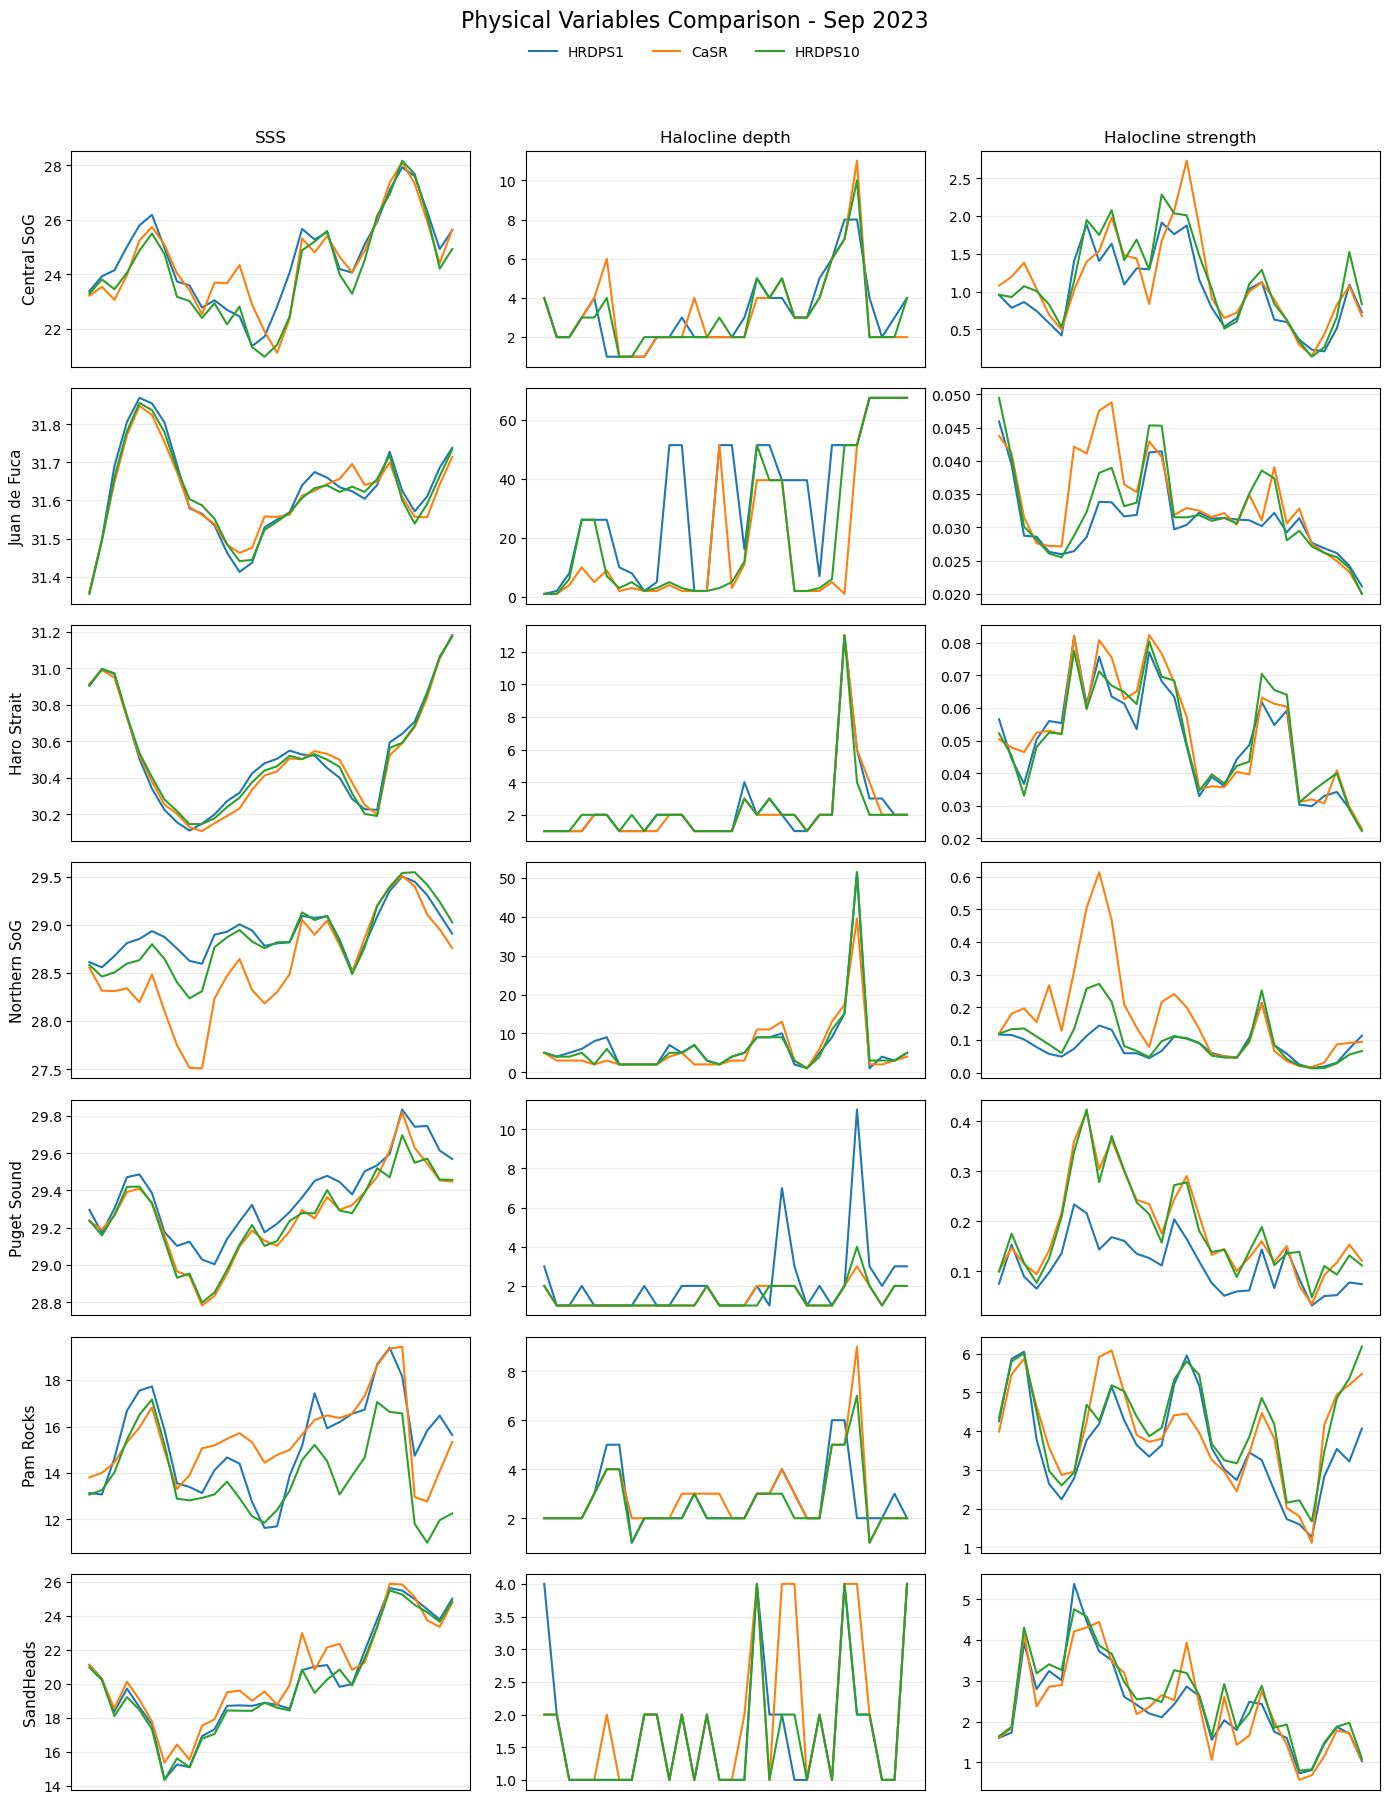

In [ ]:

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. PATH
# ============================================================

DATA_DIR = Path(
    "/home/jqiu/analysis-junqi/"
    "Analysis_Atmospheric_Forcing/"
    "Analysis_results_comparison/"
    "Analysis_4_months/Data_4_months/physical/"
)


# ============================================================
# 2. SETTINGS
# ============================================================

# month to plot
MONTH = "Sep"  # "Mar", "Jun", "Sep", "Dec"

REGIONS = [
    "Central SoG",
    "Juan_de_Fuca",
    "Haro_Strait",
    "Northern_SoG",
    "Puget_Sound",
    "Pam_Rocks",
    "SandHeads",
]

MODELS = [
    "HRDPS1",
    "CaSR",
    "HRDPS10",
]

VARIABLES = [
    ("SSS", "SSS"),
    ("halocline_depth_m", "Halocline depth"),
    (
        "halocline_strength_psu_per_m",
        "Halocline strength",
    ),
]


# ============================================================
# 3. HELPERS
# ============================================================

def safe_filename(name):
    return name.replace(" ", "_")


# ============================================================
# 4. PLOT
# ============================================================

fig, axes = plt.subplots(
    nrows=len(REGIONS),
    ncols=len(VARIABLES),
    figsize=(14, 18),
)

for row, region in enumerate(REGIONS):

    filename = (
        DATA_DIR /
        f"{safe_filename(region)}_physical.csv"
    )

    print(f"Reading: {filename}")

    if not filename.exists():
        print(f"WARNING: file not found: {filename}")
        continue

    df = pd.read_csv(filename)

    # Select the specified month
    df = df[df["month"] == MONTH].copy()

    if df.empty:
        print(f"WARNING: no data for {MONTH} in {region}")
        continue

    # Sort by date
    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values("date")

    x = df["date"]

    for col, (var_name, var_title) in enumerate(VARIABLES):

        ax = axes[row, col]

        for model in MODELS:

            column_name = f"{model}__{var_name}"

            if column_name not in df.columns:
                print(
                    f"WARNING: missing column: {column_name}"
                )
                continue

            ax.plot(
                x,
                df[column_name],
                label=model,
                linewidth=1.5,
            )

        # Column title only on top row
        if row == 0:
            ax.set_title(var_title, fontsize=12)

        # Region name only on left column
        if col == 0:
            ax.set_ylabel(
                region.replace("_", " "),
                fontsize=11,
            )

        # Hide date labels
        ax.set_xticks([])

        ax.grid(alpha=0.25)


# ============================================================
# 5. ONE SHARED LEGEND
# ============================================================

# Collect legend handles from all axes
legend_dict = {}

for ax in axes.flat:
    handles, labels = ax.get_legend_handles_labels()

    for handle, label in zip(handles, labels):
        legend_dict[label] = handle

fig.legend(
    legend_dict.values(),
    legend_dict.keys(),
    loc="upper center",
    ncol=len(MODELS),
    bbox_to_anchor=(0.5, 0.985),
    frameon=False,
)

fig.suptitle(
    f"Physical {MONTH} 2023",
    fontsize=16,
    y=0.998,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)





plt.show()

Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/physical/Central_SoG_physical.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/physical/Juan_de_Fuca_physical.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/physical/Haro_Strait_physical.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/physical/Northern_SoG_physical.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/physical/Puget_Sound_physical.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/physical/Pam_Rocks_physical.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmosphe

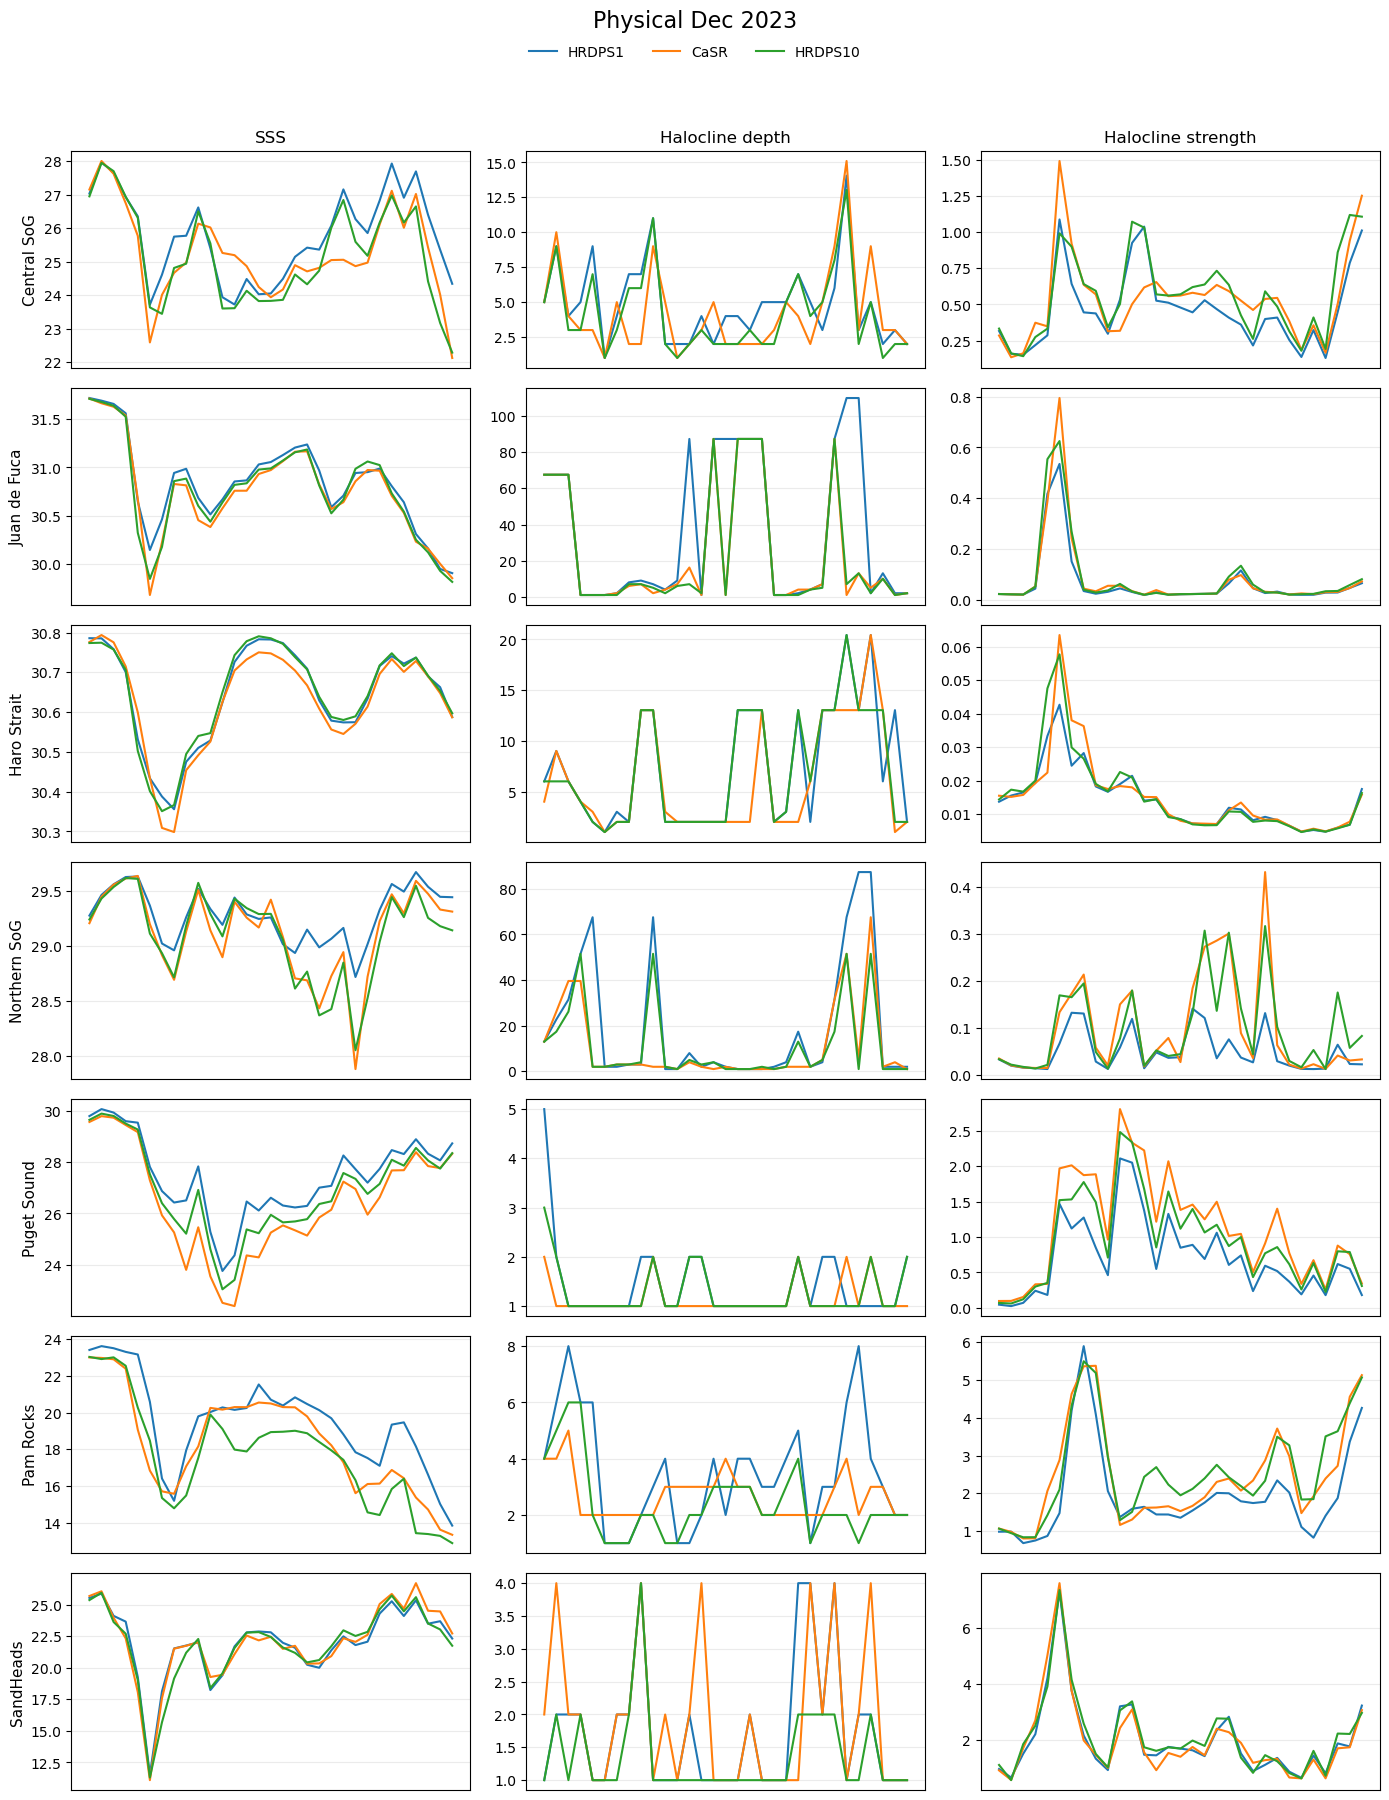

In [9]:

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. PATH
# ============================================================

DATA_DIR = Path(
    "/home/jqiu/analysis-junqi/"
    "Analysis_Atmospheric_Forcing/"
    "Analysis_results_comparison/"
    "Analysis_4_months/Data_4_months/physical/"
)


# ============================================================
# 2. SETTINGS
# ============================================================

# month to plot
MONTH = "Dec"  # "Mar", "Jun", "Sep", "Dec"

REGIONS = [
    "Central SoG",
    "Juan_de_Fuca",
    "Haro_Strait",
    "Northern_SoG",
    "Puget_Sound",
    "Pam_Rocks",
    "SandHeads",
]

MODELS = [
    "HRDPS1",
    "CaSR",
    "HRDPS10",
]

VARIABLES = [
    ("SSS", "SSS"),
    ("halocline_depth_m", "Halocline depth"),
    (
        "halocline_strength_psu_per_m",
        "Halocline strength",
    ),
]


# ============================================================
# 3. HELPERS
# ============================================================

def safe_filename(name):
    return name.replace(" ", "_")


# ============================================================
# 4. PLOT
# ============================================================

fig, axes = plt.subplots(
    nrows=len(REGIONS),
    ncols=len(VARIABLES),
    figsize=(14, 18),
)

for row, region in enumerate(REGIONS):

    filename = (
        DATA_DIR /
        f"{safe_filename(region)}_physical.csv"
    )

    print(f"Reading: {filename}")

    if not filename.exists():
        print(f"WARNING: file not found: {filename}")
        continue

    df = pd.read_csv(filename)

    # Select the specified month
    df = df[df["month"] == MONTH].copy()

    if df.empty:
        print(f"WARNING: no data for {MONTH} in {region}")
        continue

    # Sort by date
    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values("date")

    x = df["date"]

    for col, (var_name, var_title) in enumerate(VARIABLES):

        ax = axes[row, col]

        for model in MODELS:

            column_name = f"{model}__{var_name}"

            if column_name not in df.columns:
                print(
                    f"WARNING: missing column: {column_name}"
                )
                continue

            ax.plot(
                x,
                df[column_name],
                label=model,
                linewidth=1.5,
            )

        # Column title only on top row
        if row == 0:
            ax.set_title(var_title, fontsize=12)

        # Region name only on left column
        if col == 0:
            ax.set_ylabel(
                region.replace("_", " "),
                fontsize=11,
            )

        # Hide date labels
        ax.set_xticks([])

        ax.grid(alpha=0.25)


# ============================================================
# 5. ONE SHARED LEGEND
# ============================================================

# Collect legend handles from all axes
legend_dict = {}

for ax in axes.flat:
    handles, labels = ax.get_legend_handles_labels()

    for handle, label in zip(handles, labels):
        legend_dict[label] = handle

fig.legend(
    legend_dict.values(),
    legend_dict.keys(),
    loc="upper center",
    ncol=len(MODELS),
    bbox_to_anchor=(0.5, 0.985),
    frameon=False,
)

fig.suptitle(
    f"Physical {MONTH} 2023",
    fontsize=16,
    y=0.998,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)





plt.show()

### Bio

Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/biological/Central_SoG_biological.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/biological/Juan_de_Fuca_biological.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/biological/Haro_Strait_biological.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/biological/Northern_SoG_biological.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/biological/Puget_Sound_biological.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/biological/Pam_Rocks_biological.csv
Reading: /home/jqiu/analysis

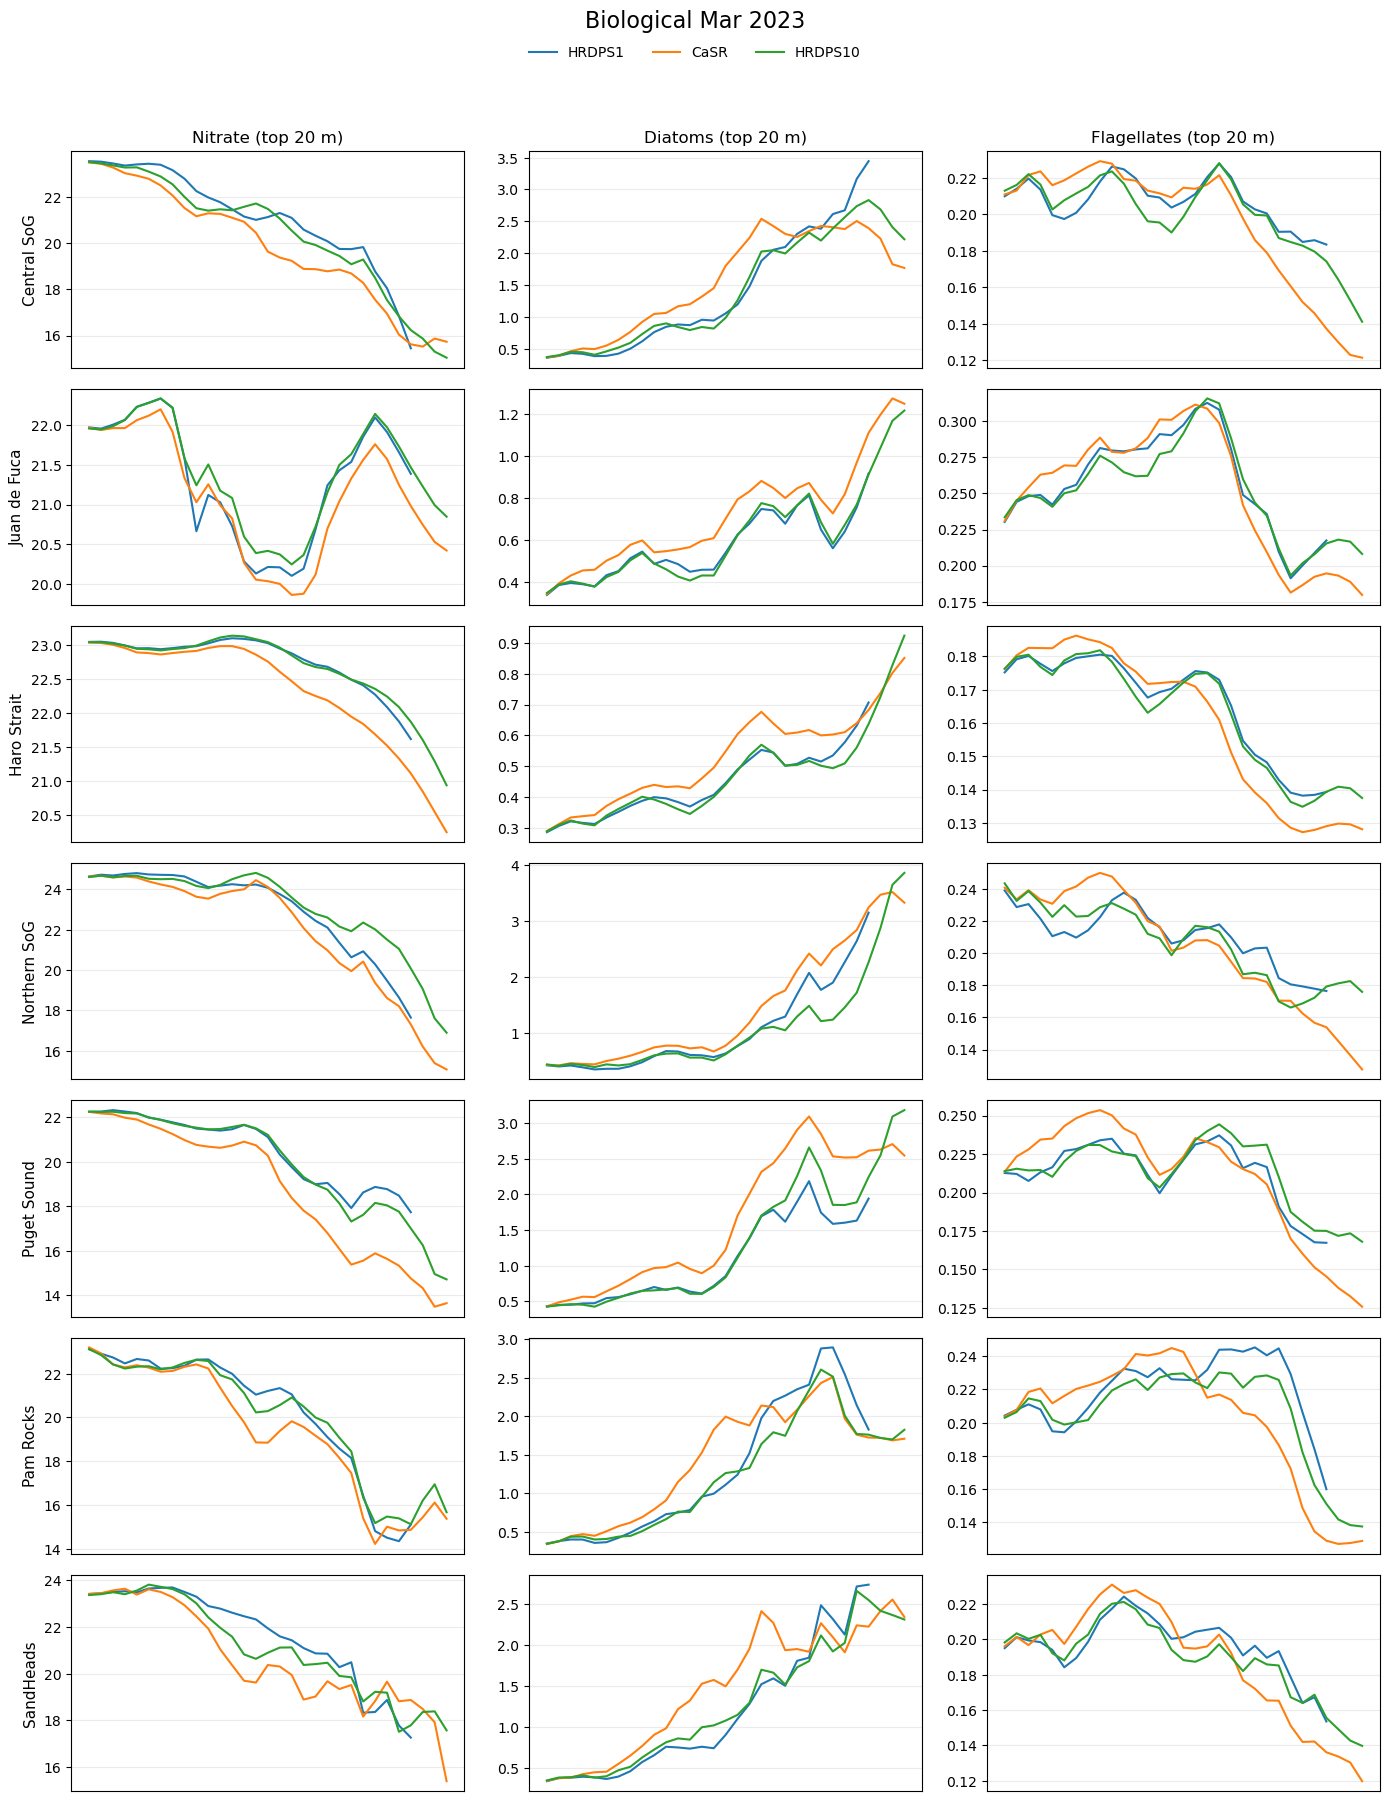

In [11]:

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. PATH
# ============================================================

DATA_DIR = Path(
    "/home/jqiu/analysis-junqi/"
    "Analysis_Atmospheric_Forcing/"
    "Analysis_results_comparison/"
    "Analysis_4_months/Data_4_months/biological/"
)


# ============================================================
# 2. SETTINGS
# ============================================================

# month to plot
MONTH = "Mar"  # "Mar", "Jun", "Sep", "Dec"

REGIONS = [
    "Central SoG",
    "Juan_de_Fuca",
    "Haro_Strait",
    "Northern_SoG",
    "Puget_Sound",
    "Pam_Rocks",
    "SandHeads",
]

MODELS = [
    "HRDPS1",
    "CaSR",
    "HRDPS10",
]

VARIABLES = [
    ("nitrate_top20", "Nitrate (top 20 m)"),
    ("diatoms_top20", "Diatoms (top 20 m)"),
    ("flagellates_top20", "Flagellates (top 20 m)"),
]


# ============================================================
# 3. HELPERS
# ============================================================

def safe_filename(name):
    return name.replace(" ", "_")


# ============================================================
# 4. PLOT
# ============================================================

fig, axes = plt.subplots(
    nrows=len(REGIONS),
    ncols=len(VARIABLES),
    figsize=(14, 18),
)

for row, region in enumerate(REGIONS):

    filename = (
        DATA_DIR /
        f"{safe_filename(region)}_biological.csv"
    )

    print(f"Reading: {filename}")

    if not filename.exists():
        print(f"WARNING: file not found: {filename}")
        continue

    df = pd.read_csv(filename)

    # Select the specified month
    df = df[df["month"] == MONTH].copy()

    if df.empty:
        print(f"WARNING: no data for {MONTH} in {region}")
        continue

    # Sort by date
    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values("date")

    x = df["date"]

    for col, (var_name, var_title) in enumerate(VARIABLES):

        ax = axes[row, col]

        for model in MODELS:

            column_name = f"{model}__{var_name}"

            if column_name not in df.columns:
                print(
                    f"WARNING: missing column: {column_name}"
                )
                continue

            ax.plot(
                x,
                df[column_name],
                label=model,
                linewidth=1.5,
            )

        # Column title only on top row
        if row == 0:
            ax.set_title(var_title, fontsize=12)

        # Region name only on left column
        if col == 0:
            ax.set_ylabel(
                region.replace("_", " "),
                fontsize=11,
            )

        # Hide date labels
        ax.set_xticks([])

        ax.grid(alpha=0.25)


# ============================================================
# 5. ONE SHARED LEGEND
# ============================================================

# Collect legend handles from all axes
legend_dict = {}

for ax in axes.flat:
    handles, labels = ax.get_legend_handles_labels()

    for handle, label in zip(handles, labels):
        legend_dict[label] = handle

fig.legend(
    legend_dict.values(),
    legend_dict.keys(),
    loc="upper center",
    ncol=len(MODELS),
    bbox_to_anchor=(0.5, 0.985),
    frameon=False,
)

fig.suptitle(
    f"Biological {MONTH} 2023",
    fontsize=16,
    y=0.998,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)



plt.show()


Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/biological/Central_SoG_biological.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/biological/Juan_de_Fuca_biological.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/biological/Haro_Strait_biological.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/biological/Northern_SoG_biological.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/biological/Puget_Sound_biological.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/biological/Pam_Rocks_biological.csv
Reading: /home/jqiu/analysis

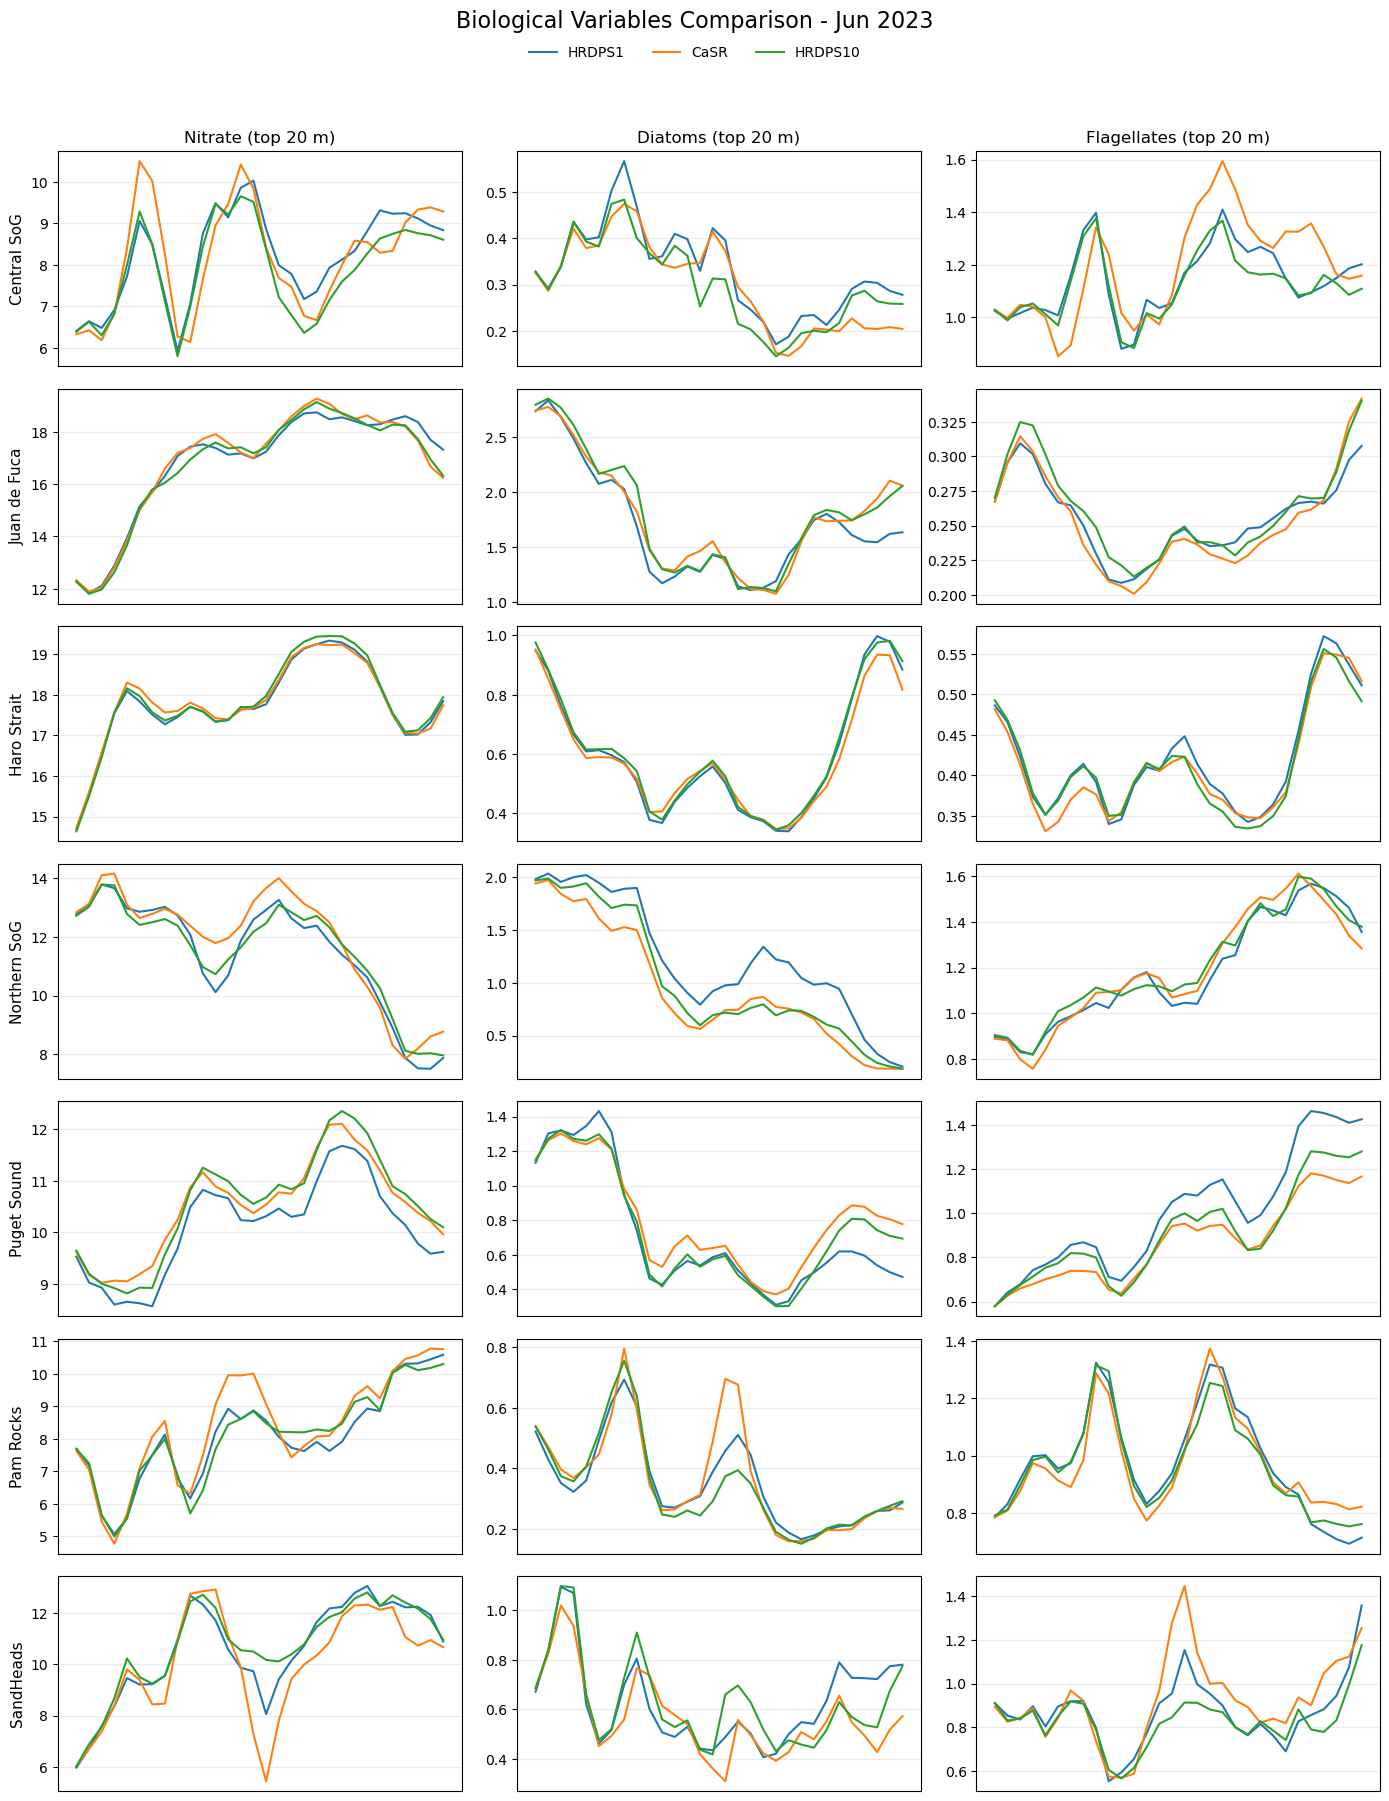

In [12]:

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. PATH
# ============================================================

DATA_DIR = Path(
    "/home/jqiu/analysis-junqi/"
    "Analysis_Atmospheric_Forcing/"
    "Analysis_results_comparison/"
    "Analysis_4_months/Data_4_months/biological/"
)


# ============================================================
# 2. SETTINGS
# ============================================================

# month to plot
MONTH = "Jun"  # "Mar", "Jun", "Sep", "Dec"

REGIONS = [
    "Central SoG",
    "Juan_de_Fuca",
    "Haro_Strait",
    "Northern_SoG",
    "Puget_Sound",
    "Pam_Rocks",
    "SandHeads",
]

MODELS = [
    "HRDPS1",
    "CaSR",
    "HRDPS10",
]

VARIABLES = [
    ("nitrate_top20", "Nitrate (top 20 m)"),
    ("diatoms_top20", "Diatoms (top 20 m)"),
    ("flagellates_top20", "Flagellates (top 20 m)"),
]


# ============================================================
# 3. HELPERS
# ============================================================

def safe_filename(name):
    return name.replace(" ", "_")


# ============================================================
# 4. PLOT
# ============================================================

fig, axes = plt.subplots(
    nrows=len(REGIONS),
    ncols=len(VARIABLES),
    figsize=(14, 18),
)

for row, region in enumerate(REGIONS):

    filename = (
        DATA_DIR /
        f"{safe_filename(region)}_biological.csv"
    )

    print(f"Reading: {filename}")

    if not filename.exists():
        print(f"WARNING: file not found: {filename}")
        continue

    df = pd.read_csv(filename)

    # Select the specified month
    df = df[df["month"] == MONTH].copy()

    if df.empty:
        print(f"WARNING: no data for {MONTH} in {region}")
        continue

    # Sort by date
    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values("date")

    x = df["date"]

    for col, (var_name, var_title) in enumerate(VARIABLES):

        ax = axes[row, col]

        for model in MODELS:

            column_name = f"{model}__{var_name}"

            if column_name not in df.columns:
                print(
                    f"WARNING: missing column: {column_name}"
                )
                continue

            ax.plot(
                x,
                df[column_name],
                label=model,
                linewidth=1.5,
            )

        # Column title only on top row
        if row == 0:
            ax.set_title(var_title, fontsize=12)

        # Region name only on left column
        if col == 0:
            ax.set_ylabel(
                region.replace("_", " "),
                fontsize=11,
            )

        # Hide date labels
        ax.set_xticks([])

        ax.grid(alpha=0.25)


# ============================================================
# 5. ONE SHARED LEGEND
# ============================================================

# Collect legend handles from all axes
legend_dict = {}

for ax in axes.flat:
    handles, labels = ax.get_legend_handles_labels()

    for handle, label in zip(handles, labels):
        legend_dict[label] = handle

fig.legend(
    legend_dict.values(),
    legend_dict.keys(),
    loc="upper center",
    ncol=len(MODELS),
    bbox_to_anchor=(0.5, 0.985),
    frameon=False,
)

fig.suptitle(
    f"Biological Variables Comparison - {MONTH} 2023",
    fontsize=16,
    y=0.998,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)



plt.show()

Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/biological/Central_SoG_biological.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/biological/Juan_de_Fuca_biological.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/biological/Haro_Strait_biological.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/biological/Northern_SoG_biological.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/biological/Puget_Sound_biological.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/biological/Pam_Rocks_biological.csv
Reading: /home/jqiu/analysis

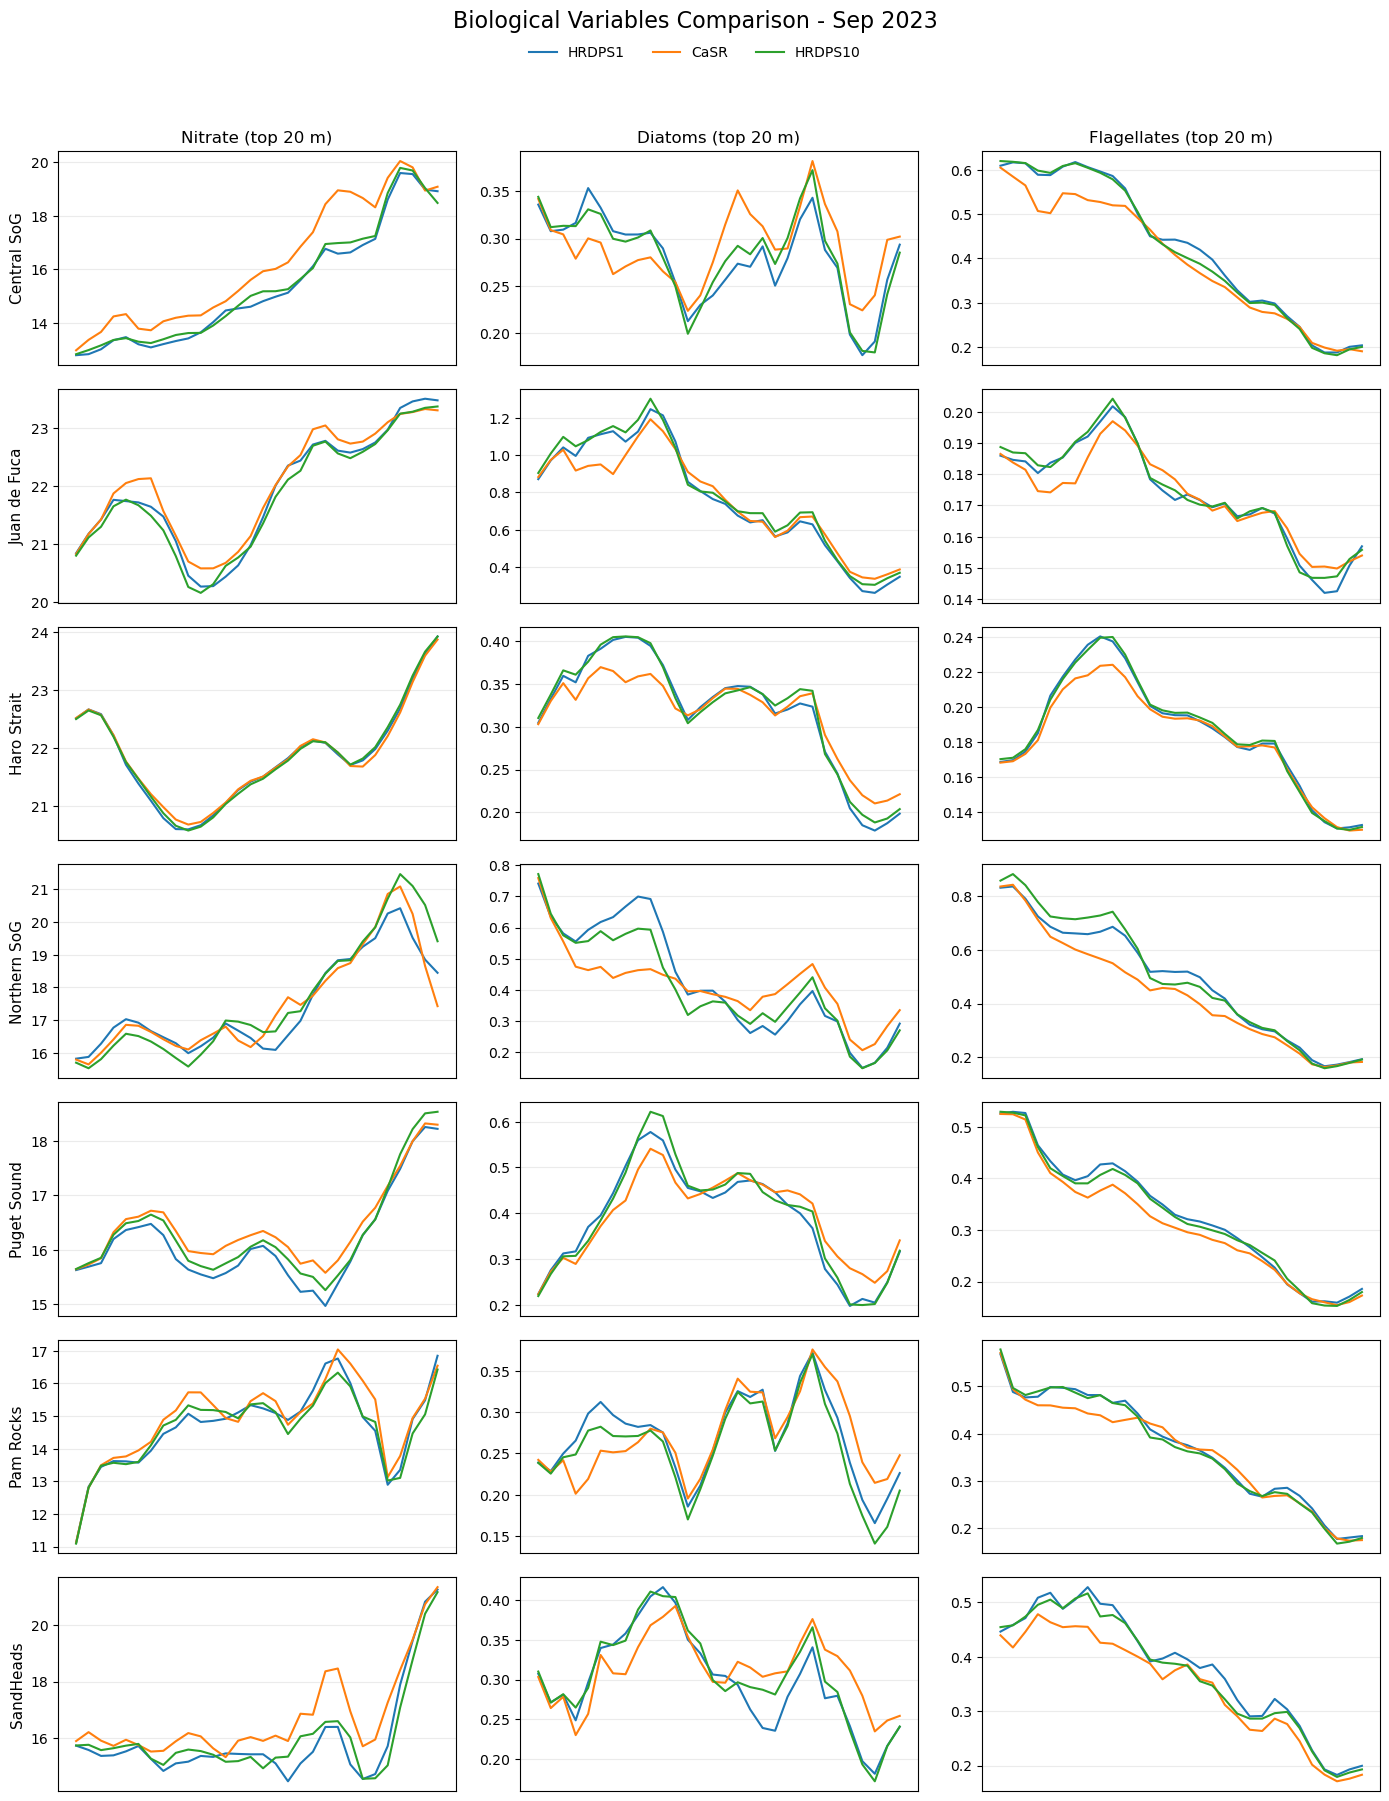

In [13]:

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. PATH
# ============================================================

DATA_DIR = Path(
    "/home/jqiu/analysis-junqi/"
    "Analysis_Atmospheric_Forcing/"
    "Analysis_results_comparison/"
    "Analysis_4_months/Data_4_months/biological/"
)


# ============================================================
# 2. SETTINGS
# ============================================================

# month to plot
MONTH = "Sep"  # "Mar", "Jun", "Sep", "Dec"

REGIONS = [
    "Central SoG",
    "Juan_de_Fuca",
    "Haro_Strait",
    "Northern_SoG",
    "Puget_Sound",
    "Pam_Rocks",
    "SandHeads",
]

MODELS = [
    "HRDPS1",
    "CaSR",
    "HRDPS10",
]

VARIABLES = [
    ("nitrate_top20", "Nitrate (top 20 m)"),
    ("diatoms_top20", "Diatoms (top 20 m)"),
    ("flagellates_top20", "Flagellates (top 20 m)"),
]


# ============================================================
# 3. HELPERS
# ============================================================

def safe_filename(name):
    return name.replace(" ", "_")


# ============================================================
# 4. PLOT
# ============================================================

fig, axes = plt.subplots(
    nrows=len(REGIONS),
    ncols=len(VARIABLES),
    figsize=(14, 18),
)

for row, region in enumerate(REGIONS):

    filename = (
        DATA_DIR /
        f"{safe_filename(region)}_biological.csv"
    )

    print(f"Reading: {filename}")

    if not filename.exists():
        print(f"WARNING: file not found: {filename}")
        continue

    df = pd.read_csv(filename)

    # Select the specified month
    df = df[df["month"] == MONTH].copy()

    if df.empty:
        print(f"WARNING: no data for {MONTH} in {region}")
        continue

    # Sort by date
    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values("date")

    x = df["date"]

    for col, (var_name, var_title) in enumerate(VARIABLES):

        ax = axes[row, col]

        for model in MODELS:

            column_name = f"{model}__{var_name}"

            if column_name not in df.columns:
                print(
                    f"WARNING: missing column: {column_name}"
                )
                continue

            ax.plot(
                x,
                df[column_name],
                label=model,
                linewidth=1.5,
            )

        # Column title only on top row
        if row == 0:
            ax.set_title(var_title, fontsize=12)

        # Region name only on left column
        if col == 0:
            ax.set_ylabel(
                region.replace("_", " "),
                fontsize=11,
            )

        # Hide date labels
        ax.set_xticks([])

        ax.grid(alpha=0.25)


# ============================================================
# 5. ONE SHARED LEGEND
# ============================================================

# Collect legend handles from all axes
legend_dict = {}

for ax in axes.flat:
    handles, labels = ax.get_legend_handles_labels()

    for handle, label in zip(handles, labels):
        legend_dict[label] = handle

fig.legend(
    legend_dict.values(),
    legend_dict.keys(),
    loc="upper center",
    ncol=len(MODELS),
    bbox_to_anchor=(0.5, 0.985),
    frameon=False,
)

fig.suptitle(
    f"Biological Variables Comparison - {MONTH} 2023",
    fontsize=16,
    y=0.998,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)



plt.show()

Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/biological/Central_SoG_biological.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/biological/Juan_de_Fuca_biological.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/biological/Haro_Strait_biological.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/biological/Northern_SoG_biological.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/biological/Puget_Sound_biological.csv
Reading: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_results_comparison/Analysis_4_months/Data_4_months/biological/Pam_Rocks_biological.csv
Reading: /home/jqiu/analysis

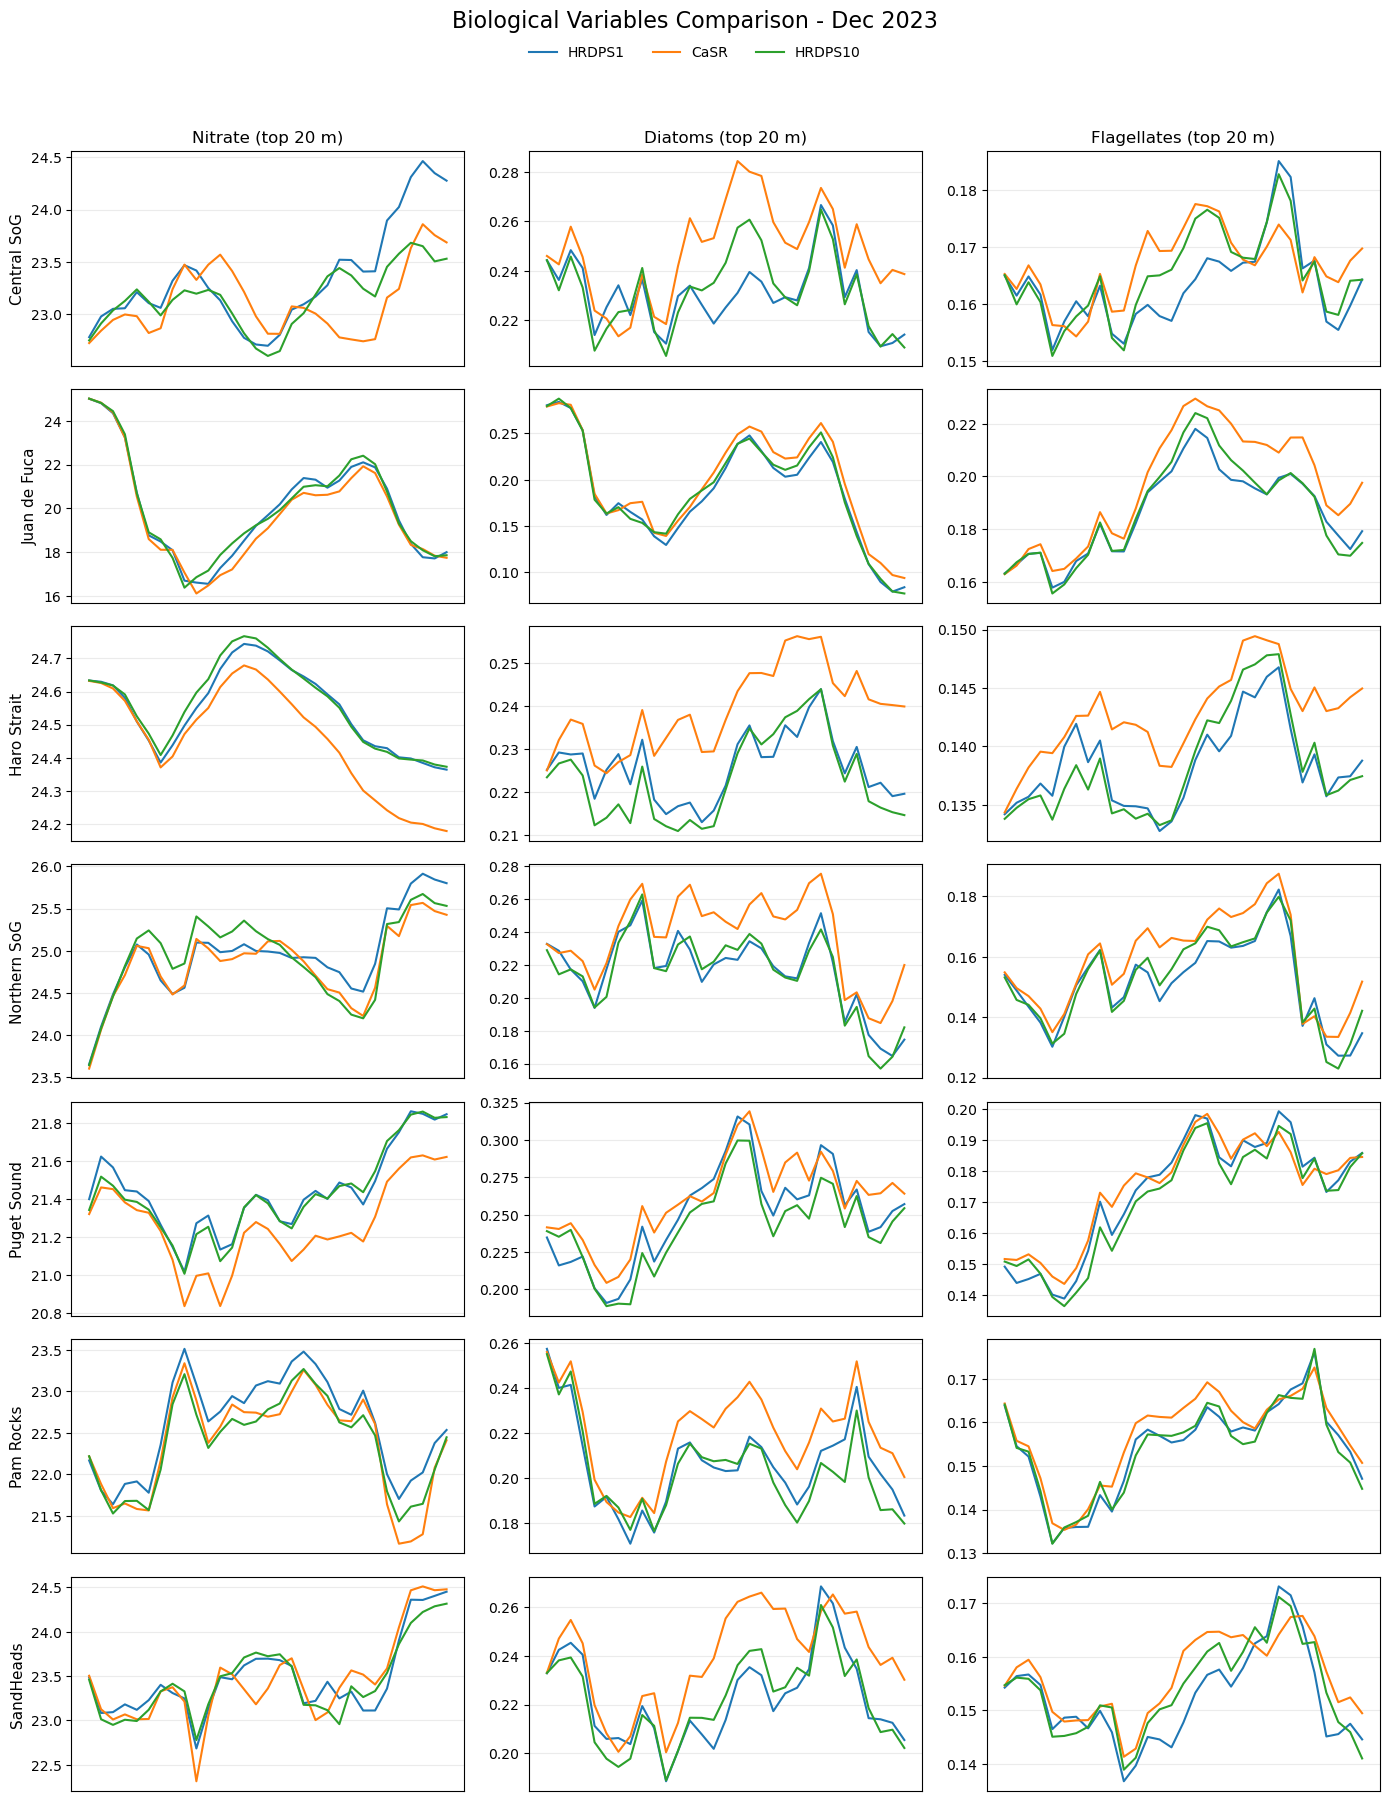

In [14]:

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. PATH
# ============================================================

DATA_DIR = Path(
    "/home/jqiu/analysis-junqi/"
    "Analysis_Atmospheric_Forcing/"
    "Analysis_results_comparison/"
    "Analysis_4_months/Data_4_months/biological/"
)


# ============================================================
# 2. SETTINGS
# ============================================================

# month to plot
MONTH = "Dec"  # "Mar", "Jun", "Sep", "Dec"

REGIONS = [
    "Central SoG",
    "Juan_de_Fuca",
    "Haro_Strait",
    "Northern_SoG",
    "Puget_Sound",
    "Pam_Rocks",
    "SandHeads",
]

MODELS = [
    "HRDPS1",
    "CaSR",
    "HRDPS10",
]

VARIABLES = [
    ("nitrate_top20", "Nitrate (top 20 m)"),
    ("diatoms_top20", "Diatoms (top 20 m)"),
    ("flagellates_top20", "Flagellates (top 20 m)"),
]


# ============================================================
# 3. HELPERS
# ============================================================

def safe_filename(name):
    return name.replace(" ", "_")


# ============================================================
# 4. PLOT
# ============================================================

fig, axes = plt.subplots(
    nrows=len(REGIONS),
    ncols=len(VARIABLES),
    figsize=(14, 18),
)

for row, region in enumerate(REGIONS):

    filename = (
        DATA_DIR /
        f"{safe_filename(region)}_biological.csv"
    )

    print(f"Reading: {filename}")

    if not filename.exists():
        print(f"WARNING: file not found: {filename}")
        continue

    df = pd.read_csv(filename)

    # Select the specified month
    df = df[df["month"] == MONTH].copy()

    if df.empty:
        print(f"WARNING: no data for {MONTH} in {region}")
        continue

    # Sort by date
    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values("date")

    x = df["date"]

    for col, (var_name, var_title) in enumerate(VARIABLES):

        ax = axes[row, col]

        for model in MODELS:

            column_name = f"{model}__{var_name}"

            if column_name not in df.columns:
                print(
                    f"WARNING: missing column: {column_name}"
                )
                continue

            ax.plot(
                x,
                df[column_name],
                label=model,
                linewidth=1.5,
            )

        # Column title only on top row
        if row == 0:
            ax.set_title(var_title, fontsize=12)

        # Region name only on left column
        if col == 0:
            ax.set_ylabel(
                region.replace("_", " "),
                fontsize=11,
            )

        # Hide date labels
        ax.set_xticks([])

        ax.grid(alpha=0.25)


# ============================================================
# 5. ONE SHARED LEGEND
# ============================================================

# Collect legend handles from all axes
legend_dict = {}

for ax in axes.flat:
    handles, labels = ax.get_legend_handles_labels()

    for handle, label in zip(handles, labels):
        legend_dict[label] = handle

fig.legend(
    legend_dict.values(),
    legend_dict.keys(),
    loc="upper center",
    ncol=len(MODELS),
    bbox_to_anchor=(0.5, 0.985),
    frameon=False,
)

fig.suptitle(
    f"Biological Variables Comparison - {MONTH} 2023",
    fontsize=16,
    y=0.998,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)



plt.show()

### Wind Stress 

Reading: /ocean/jqiu/results/Flux/flux_00mar23_hrdps1/SalishSea_1d_20230301_20230328_sbfx_T.nc
Reading: /ocean/jqiu/results/Flux/flux_00mar23_CaSR/SalishSea_1d_20230301_20230331_sbfx_T.nc
Reading: /ocean/jqiu/results/Flux/flux_00mar23_hrdps10/SalishSea_1d_20230301_20230331_sbfx_T.nc


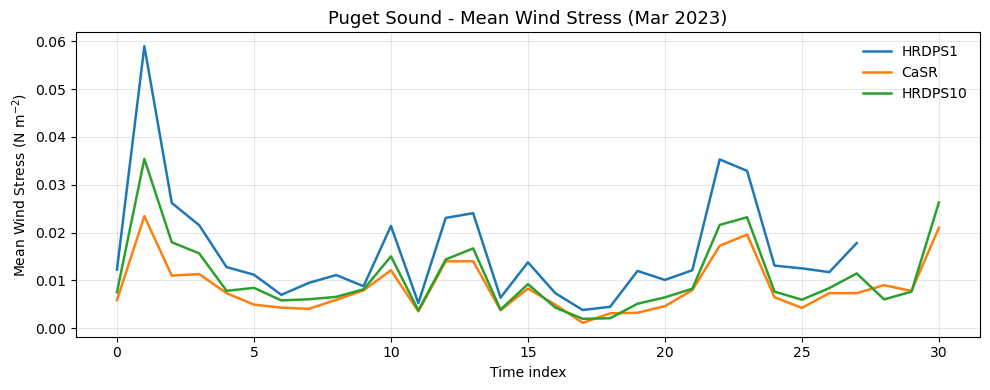

In [20]:

from pathlib import Path

import xarray as xr
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 1. FILE PATHS
# ============================================================

EXPERIMENTS_HEAD = {
    "HRDPS1": {
        "Mar": "/ocean/jqiu/results/Flux/flux_00mar23_hrdps1/SalishSea_1d_20230301_20230328",
        "Jun": "/ocean/jqiu/results/Flux/flux_00jun23_hrdps1/SalishSea_1d_20230601_20230630",
        "Sep": "/ocean/jqiu/results/Flux/flux_00sep23_hrdps1/SalishSea_1d_20230901_20230930",
        "Dec": "/ocean/jqiu/results/Flux/flux_00dec23_hrdps1/SalishSea_1d_20231201_20231231",
    },
    "CaSR": {
        "Mar": "/ocean/jqiu/results/Flux/flux_00mar23_CaSR/SalishSea_1d_20230301_20230331",
        "Jun": "/ocean/jqiu/results/Flux/flux_00jun23_CaSR/SalishSea_1d_20230601_20230630",
        "Sep": "/ocean/jqiu/results/Flux/flux_00sep23_CaSR/SalishSea_1d_20230901_20230930",
        "Dec": "/ocean/jqiu/results/Flux/flux_00dec23_CaSR/SalishSea_1d_20231201_20231231",
    },
    "HRDPS10": {
        "Mar": "/ocean/jqiu/results/Flux/flux_00mar23_hrdps10/SalishSea_1d_20230301_20230331",
        "Jun": "/ocean/jqiu/results/Flux/flux_00jun23_hrdps10/SalishSea_1d_20230601_20230630",
        "Sep": "/ocean/jqiu/results/Flux/flux_00sep23_hrdps10/SalishSea_1d_20230901_20230930",
        "Dec": "/ocean/jqiu/results/Flux/flux_00dec23_hrdps10/SalishSea_1d_20231201_20231231",
    },
}


# ============================================================
# 2. SETTINGS
# ============================================================

# Change month here
MONTH = "Mar"  # "Mar", "Jun", "Sep", "Dec"

MODELS = ["HRDPS1", "CaSR", "HRDPS10"]

COLORS = {
    "HRDPS1": "tab:blue",
    "CaSR": "tab:orange",
    "HRDPS10": "tab:green",
}

# Puget Sound
j0, j1, i0, i1 = 75, 125, 225, 280

VARIABLE = "wind stress"
FILE_SUFFIX = "_sbfx_T.nc"


# ============================================================
# 3. READ DATA
# ============================================================

results = {}

for model in MODELS:

    file_path = Path(
        EXPERIMENTS_HEAD[model][MONTH] + FILE_SUFFIX
    )

    print(f"Reading: {file_path}")

    if not file_path.exists():
        print(f"WARNING: file not found: {file_path}")
        continue

    with xr.open_dataset(file_path) as ds:

        if VARIABLE not in ds:
            print(
                f"WARNING: {VARIABLE} not found in {file_path}"
            )
            continue

        # Select Puget Sound
        data = ds[VARIABLE].isel(
            y=slice(j0, j1),
            x=slice(i0, i1)
        )

        # Remove invalid values
        data = data.where(np.isfinite(data))

        # Spatial mean for each time index
        mean_data = data.mean(
            dim=["y", "x"],
            skipna=True
        ).values

        results[model] = mean_data


# ============================================================
# 4. PLOT: ONE FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(10, 4))

for model in MODELS:

    if model not in results:
        continue

    mean_data = results[model]

    # Use time index
    time_idx = np.arange(len(mean_data))

    ax.plot(
        time_idx,
        mean_data,
        label=model,
        color=COLORS[model],
        linewidth=1.8
    )


# ============================================================
# 5. FORMATTING
# ============================================================

ax.set_title(
    f"Puget Sound - Mean Wind Stress ({MONTH} 2023)",
    fontsize=13
)

ax.set_xlabel("Time index")

ax.set_ylabel(
    "Mean Wind Stress (N m$^{-2}$)"
)

ax.legend(frameon=False)

ax.grid(alpha=0.3)

plt.tight_layout()

plt.show()



Reading: /ocean/jqiu/results/Flux/flux_00jun23_hrdps1/SalishSea_1d_20230601_20230630_sbfx_T.nc
Reading: /ocean/jqiu/results/Flux/flux_00jun23_CaSR/SalishSea_1d_20230601_20230630_sbfx_T.nc
Reading: /ocean/jqiu/results/Flux/flux_00jun23_hrdps10/SalishSea_1d_20230601_20230630_sbfx_T.nc
Reading: /ocean/jqiu/results/Flux/flux_00sep23_hrdps1/SalishSea_1d_20230901_20230930_sbfx_T.nc
Reading: /ocean/jqiu/results/Flux/flux_00sep23_CaSR/SalishSea_1d_20230901_20230930_sbfx_T.nc
Reading: /ocean/jqiu/results/Flux/flux_00sep23_hrdps10/SalishSea_1d_20230901_20230930_sbfx_T.nc
Reading: /ocean/jqiu/results/Flux/flux_00dec23_hrdps1/SalishSea_1d_20231201_20231231_sbfx_T.nc
Reading: /ocean/jqiu/results/Flux/flux_00dec23_CaSR/SalishSea_1d_20231201_20231231_sbfx_T.nc
Reading: /ocean/jqiu/results/Flux/flux_00dec23_hrdps10/SalishSea_1d_20231201_20231231_sbfx_T.nc


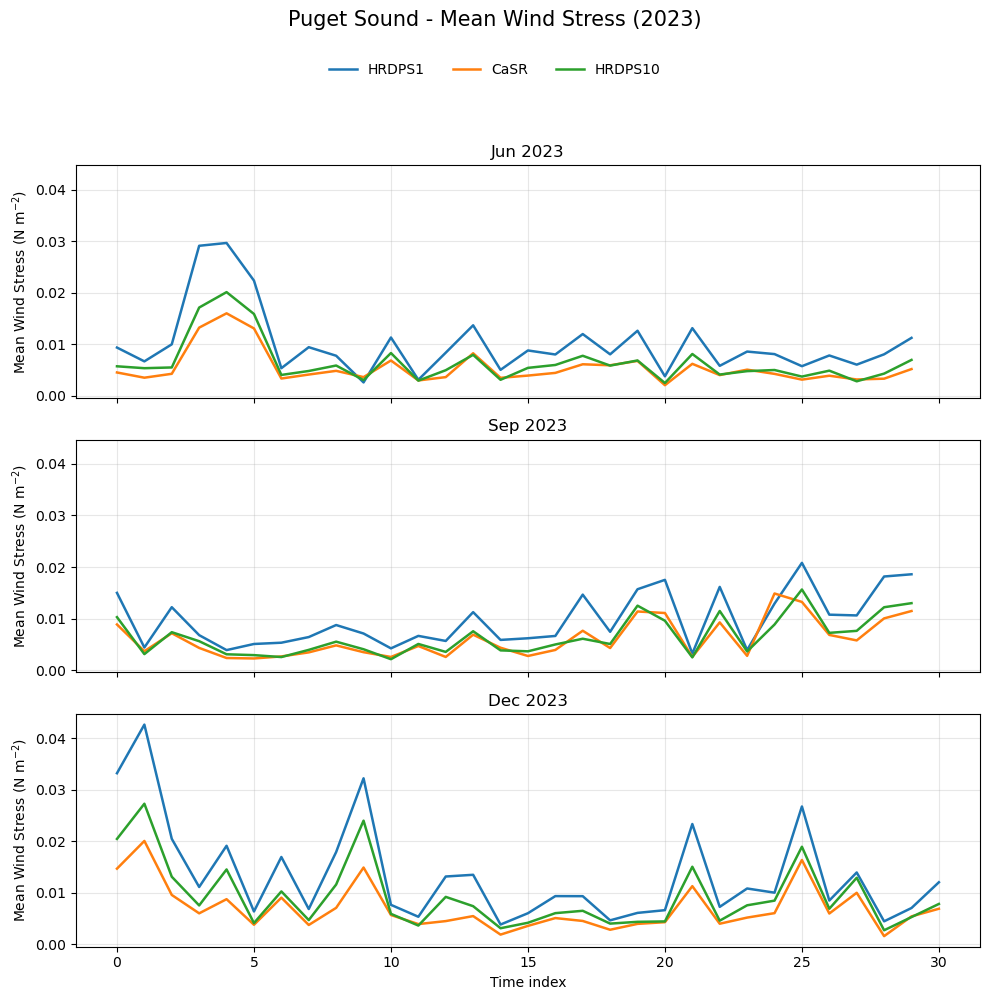

In [21]:

from pathlib import Path

import xarray as xr
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 1. FILE PATHS
# ============================================================

EXPERIMENTS_HEAD = {
    "HRDPS1": {
        "Mar": "/ocean/jqiu/results/Flux/flux_00mar23_hrdps1/SalishSea_1d_20230301_20230328",
        "Jun": "/ocean/jqiu/results/Flux/flux_00jun23_hrdps1/SalishSea_1d_20230601_20230630",
        "Sep": "/ocean/jqiu/results/Flux/flux_00sep23_hrdps1/SalishSea_1d_20230901_20230930",
        "Dec": "/ocean/jqiu/results/Flux/flux_00dec23_hrdps1/SalishSea_1d_20231201_20231231",
    },
    "CaSR": {
        "Mar": "/ocean/jqiu/results/Flux/flux_00mar23_CaSR/SalishSea_1d_20230301_20230331",
        "Jun": "/ocean/jqiu/results/Flux/flux_00jun23_CaSR/SalishSea_1d_20230601_20230630",
        "Sep": "/ocean/jqiu/results/Flux/flux_00sep23_CaSR/SalishSea_1d_20230901_20230930",
        "Dec": "/ocean/jqiu/results/Flux/flux_00dec23_CaSR/SalishSea_1d_20231201_20231231",
    },
    "HRDPS10": {
        "Mar": "/ocean/jqiu/results/Flux/flux_00mar23_hrdps10/SalishSea_1d_20230301_20230331",
        "Jun": "/ocean/jqiu/results/Flux/flux_00jun23_hrdps10/SalishSea_1d_20230601_20230630",
        "Sep": "/ocean/jqiu/results/Flux/flux_00sep23_hrdps10/SalishSea_1d_20230901_20230930",
        "Dec": "/ocean/jqiu/results/Flux/flux_00dec23_hrdps10/SalishSea_1d_20231201_20231231",
    },
}


# ============================================================
# 2. SETTINGS
# ============================================================

MONTHS = ["Jun", "Sep", "Dec"]

MODELS = ["HRDPS1", "CaSR", "HRDPS10"]

COLORS = {
    "HRDPS1": "tab:blue",
    "CaSR": "tab:orange",
    "HRDPS10": "tab:green",
}

# Puget Sound
j0, j1, i0, i1 = 75, 125, 225, 280

VARIABLE = "wind_stress"

FILE_SUFFIX = "_sbfx_T.nc"


# ============================================================
# 3. READ DATA
# ============================================================

results = {}

for month in MONTHS:

    results[month] = {}

    for model in MODELS:

        file_path = Path(
            EXPERIMENTS_HEAD[model][month] + FILE_SUFFIX
        )

        print(f"Reading: {file_path}")

        if not file_path.exists():
            print(f"WARNING: file not found: {file_path}")
            continue

        with xr.open_dataset(file_path) as ds:

            if VARIABLE not in ds:
                print(
                    f"WARNING: {VARIABLE} not found in {file_path}"
                )
                continue

            # Select Puget Sound
            data = ds[VARIABLE].isel(
                y=slice(j0, j1),
                x=slice(i0, i1)
            )

            # Remove invalid values
            data = data.where(np.isfinite(data))

            # Spatial mean for each time index
            mean_data = data.mean(
                dim=["y", "x"],
                skipna=True
            ).values

            results[month][model] = mean_data


# ============================================================
# 4. PLOT: 3 ROWS x 1 COLUMN
# ============================================================

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(10, 10),
    sharex=True,
    sharey=True
)

for row, month in enumerate(MONTHS):

    ax = axes[row]

    for model in MODELS:

        if model not in results[month]:
            continue

        mean_data = results[month][model]

        # Use time index
        time_idx = np.arange(len(mean_data))

        ax.plot(
            time_idx,
            mean_data,
            label=model,
            color=COLORS[model],
            linewidth=1.8
        )

    ax.set_title(f"{month} 2023", fontsize=12)

    ax.set_ylabel(
        "Mean Wind Stress (N m$^{-2}$)"
    )

    ax.grid(alpha=0.3)

# X-axis label only on bottom subplot
axes[-1].set_xlabel("Time index")


# ============================================================
# 5. SHARED LEGEND
# ============================================================

legend_dict = {}

for ax in axes:
    handles, labels = ax.get_legend_handles_labels()

    for handle, label in zip(handles, labels):
        if label not in legend_dict:
            legend_dict[label] = handle

fig.legend(
    legend_dict.values(),
    legend_dict.keys(),
    loc="upper center",
    ncol=3,
    bbox_to_anchor=(0.5, 0.955),
    frameon=False
)

fig.suptitle(
    "Puget Sound - Mean Wind Stress (2023)",
    fontsize=15,
    y=0.995
)

plt.tight_layout(
    rect=[0, 0, 1, 0.91]
)

plt.show()
